# FundMatch UK — CS5079 Applied AI, Assessment 1, Task 1 (group)

**Product:** paste a research title and abstract → (1) the UKRI council most likely to fund it, with
probabilities, (2) the 10 most similar projects UKRI has already funded, with Gateway to Research (GtR)
links, and (3) a typical award range taken from those similar projects.

**Group members:** Md Shamim Mia (52536283), [Member 2], [Member 3], [Member 4]

**Data:** UKRI Gateway to Research API v7 (https://gtr.ukri.org/resources/api.html), collected with our
own code (Section 1). Contains public sector information licensed under the Open Government Licence v3.0.
No Kaggle data, GtR bulk export or GtR-Extended dataset is used.

**How to reproduce:** `pip install -r requirements.txt`, then run `python collect_gtr.py --endpoint both`
(or set `RUN_COLLECTION = True` below), `python build_dataset.py`, then run this notebook top to bottom.
All random seeds are fixed (`SEED = 42`). Heavy steps (embeddings) are cached in `data/processed/`.

**Borrowed code:** none copied. We used the official documentation of scikit-learn
(https://scikit-learn.org), sentence-transformers (https://sbert.net) and pandas as references;
`StratifiedGroupKFold`, `TfidfVectorizer`, `LogisticRegression` and `SentenceTransformer.encode`
are used as documented, without modification.

In [1]:
import os, re, json, time, gzip, glob, pickle, hashlib, platform, subprocess, sys, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.dummy import DummyClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, top_k_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)
HERE = os.path.abspath(".")
RAW, PROC, FIG, MODELS = "data/raw", "data/processed", "figures", "models"
for d in (PROC, FIG, MODELS):
    os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]  # colour-blind safe (Okabe-Ito)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

python 3.13.5 | numpy 2.5.5 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Data collection (own code, GtR API)

The cell below is the full source of `collect_gtr.py`. It pages through `/projects` and `/funds`
(100 records per page, the API maximum), waits at least 1 s between requests per endpoint, retries with
exponential back-off on HTTP 429/5xx, and caches every page as gzipped JSON so a stopped run resumes.
Award amounts are **not** on project records, so `/funds` is collected too and joined by project id.
Lead organisation names come from `/organisations`. Collection is switched off by default because the
cached raw pages are supplied; set `RUN_COLLECTION = True` to repeat it (about 30 min per endpoint).

In [2]:
# ---- source of collect_gtr.py (also runnable from the command line) ----
"""
collect_gtr.py - collect UKRI Gateway to Research (GtR) data with our own code.

CS5079 Applied AI, Assessment 1, Task 1 (group project "FundMatch UK").

What it does
------------
1. Pages through the public GtR API v7 endpoint `/projects` (100 records per page,
   the maximum the API accepts) and caches every page as gzipped JSON under
   data/raw/projects/page_XXXXX.json.gz.
2. Pages through `/funds` and `/organisations` the same way. Award amounts are NOT
   stored on project records; each fund record links to its project with a
   `rel="FUNDED"` link, so we join funds to projects by project id later
   (see build_dataset.py).

Politeness / robustness
-----------------------
* A fixed minimum gap between requests per endpoint (default 1.0 s, i.e. about
  1 request per second, well under GtR's published limit).
* Retries with exponential back-off on network errors, HTTP 429 and 5xx.
* Resumable: pages already on disk are skipped, so the script can be stopped and
  rerun at any time ("caching" + "checkpointing").
* A JSON log (data/raw/collection_log.json) records date, totals and timings.

No API key is needed. Data is (c) UKRI, Open Government Licence v3.0.
No ready-made dataset (Kaggle, GtR-Extended, bulk CSV export) is used.

Usage
-----
    python collect_gtr.py --endpoint projects            # all pages
    python collect_gtr.py --endpoint funds --max-pages 50
    python collect_gtr.py --endpoint both --delay 1.0   # projects + funds
    python collect_gtr.py --endpoint organisations      # lead organisation names

Written by the group; the retry pattern follows the standard `requests`
documentation idea of back-off (https://requests.readthedocs.io) but is our own code.
"""
import argparse
import gzip
import json
import os
import threading
import time
from datetime import datetime, timezone

import requests

BASE = "https://gtr.ukri.org/gtr/api"
HEADERS = {
    "Accept": "application/vnd.rcuk.gtr.json-v7",
    "User-Agent": "CS5079-student-project (University of Aberdeen; educational use)",
}
PAGE_SIZE = 100  # API maximum (requests with s>100 return HTTP 400)
# folder of this script (falls back to the working directory inside a notebook)
_HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
RAW_DIR = os.path.join(_HERE, "data", "raw")


def fetch_page(session, endpoint, page, max_retries=6, timeout=60):
    """Fetch one page of an endpoint, retrying with exponential back-off.

    Returns the decoded JSON dict. Raises RuntimeError after max_retries.
    """
    url = f"{BASE}/{endpoint}"
    params = {"p": page, "s": PAGE_SIZE}
    for attempt in range(max_retries):
        try:
            r = session.get(url, params=params, headers=HEADERS, timeout=timeout)
            if r.status_code == 200:
                return r.json()
            if r.status_code in (429, 500, 502, 503, 504):
                wait = 2 ** attempt  # 1, 2, 4, 8 ... seconds
                print(f"[{endpoint}] page {page}: HTTP {r.status_code}, retry in {wait}s")
                time.sleep(wait)
                continue
            raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")
        except (requests.ConnectionError, requests.Timeout, ValueError) as e:
            wait = 2 ** attempt
            print(f"[{endpoint}] page {page}: {type(e).__name__}, retry in {wait}s")
            time.sleep(wait)
    raise RuntimeError(f"[{endpoint}] page {page} failed after {max_retries} retries")


def page_path(endpoint, page):
    return os.path.join(RAW_DIR, endpoint, f"page_{page:05d}.json.gz")


def collect(endpoint, max_pages=None, delay=1.0, log=None):
    """Download all (or the first max_pages) pages of an endpoint into the cache."""
    os.makedirs(os.path.join(RAW_DIR, endpoint), exist_ok=True)
    session = requests.Session()
    first = fetch_page(session, endpoint, 1)
    total_pages, total_size = first["totalPages"], first["totalSize"]
    n_pages = min(total_pages, max_pages or total_pages)
    print(f"[{endpoint}] {total_size} records in {total_pages} pages; collecting {n_pages}")
    with gzip.open(page_path(endpoint, 1), "wt", encoding="utf-8") as f:
        json.dump(first, f)
    t0, fetched, last = time.time(), 1, time.time()
    for page in range(2, n_pages + 1):
        if os.path.exists(page_path(endpoint, page)):
            continue  # cached by an earlier run -> resume
        gap = time.time() - last
        if gap < delay:
            time.sleep(delay - gap)  # rate limit
        last = time.time()
        data = fetch_page(session, endpoint, page)
        tmp = page_path(endpoint, page) + ".tmp"
        with gzip.open(tmp, "wt", encoding="utf-8") as f:
            json.dump(data, f)
        os.replace(tmp, page_path(endpoint, page))  # atomic write: no half files
        fetched += 1
        if page % 50 == 0:
            print(f"[{endpoint}] page {page}/{n_pages}  ({time.time()-t0:.0f}s)", flush=True)
    if log is not None:
        log[endpoint] = {
            "collected_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "api_total_records": total_size,
            "api_total_pages": total_pages,
            "pages_requested": n_pages,
            "pages_fetched_this_run": fetched,
            "seconds": round(time.time() - t0, 1),
            "delay_s": delay,
        }


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--endpoint", choices=["projects", "funds", "organisations", "both"], default="both")
    ap.add_argument("--max-pages", type=int, default=None, help="limit pages (default: all)")
    ap.add_argument("--delay", type=float, default=1.0, help="min seconds between requests")
    args = ap.parse_args()

    log_path = os.path.join(RAW_DIR, "collection_log.json")
    log = {}
    endpoints = ["projects", "funds"] if args.endpoint == "both" else [args.endpoint]
    # The two endpoints run in parallel threads, each at ~1 req/s (<= 2 req/s total).
    threads = [threading.Thread(target=collect, args=(e, args.max_pages, args.delay, log)) for e in endpoints]
    for t in threads:
        t.start()
    for t in threads:
        t.join()
    # re-read and merge so that runs for different endpoints never overwrite each other's entries
    merged = json.load(open(log_path)) if os.path.exists(log_path) else {}
    merged.update({k: v for k, v in log.items() if k in endpoints})
    with open(log_path, "w") as f:
        json.dump(merged, f, indent=2)
    log = merged
    print("done:", json.dumps(log, indent=2))
RUN_COLLECTION = False
if RUN_COLLECTION:
    log = {}
    for ep in ("projects", "funds", "organisations"):
        collect(ep, delay=1.0, log=log)
print(json.dumps(json.load(open(os.path.join(RAW, "collection_log.json"))), indent=1))
for ep in ("projects", "funds", "organisations"):
    files = glob.glob(os.path.join(RAW, ep, "page_*.json.gz"))
    print(f"{ep:14s} cached pages: {len(files):5d}  size on disk: {sum(map(os.path.getsize, files))/1e6:6.1f} MB")

{
 "funds": {
  "collected_utc": "2026-11-23T19:31:08+00:00",
  "api_total_records": 158710,
  "api_total_pages": 1588,
  "pages_requested": 1588,
  "pages_fetched_this_run": 1588,
  "seconds": 1663.3,
  "delay_s": 1.0
 },
 "projects": {
  "collected_utc": "2026-11-23T19:35:16+00:00",
  "api_total_records": 158710,
  "api_total_pages": 1588,
  "pages_requested": 1588,
  "pages_fetched_this_run": 1588,
  "seconds": 1911.0,
  "delay_s": 1.0
 },
 "organisations": {
  "collected_utc": "2026-11-23T19:41:37+00:00",
  "api_total_records": 97102,
  "api_total_pages": 972,
  "pages_requested": 972,
  "pages_fetched_this_run": 972,
  "seconds": 1040.9,
  "delay_s": 1.0
 },
 "note": "projects and funds were collected in one run (two threads, ~1 req/s each); organisations in a second run, overlapping in time. Retries (HTTP 503) are logged in collect_stdout.log / collect_orgs_stdout.log."
}
projects       cached pages:  1588  size on disk:  300.8 MB
funds          cached pages:  1588  size on disk:

### 1.1 Build one table (join funds and organisations to projects)
Source of `build_dataset.py`: flattens the JSON, joins each `/funds` record to its project through the
fund's `rel="FUNDED"` link, and the lead organisation through the project's `rel="LEAD_ORG"` link.

In [3]:
# ---- source of build_dataset.py (also runnable from the command line) ----
"""
build_dataset.py - turn the cached raw GtR pages into one tidy table.

Reads data/raw/projects/*.json.gz, data/raw/funds/*.json.gz and (if present)
data/raw/organisations/*.json.gz written by collect_gtr.py, and writes
data/processed/gtr_projects.parquet with one row per GtR project id:

    project_id, grant_ref, title, abstract, tech_abstract, potential_impact,
    lead_funder, grant_category, status, department, lead_org_id, lead_org_name,
    fund_start, fund_end, award_gbp, fund_category, n_funds,
    research_subjects, research_topics, gtr_url

Award amounts and dates come from the /funds records, joined on the project
id found in each fund's rel="FUNDED" link (they are not on project records).
"""
import glob
import gzip
import json
import os

import pandas as pd

# folder of this script (falls back to the working directory inside a notebook)
_HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
HERE = _HERE
RAW = os.path.join(HERE, "data", "raw")
OUT = os.path.join(HERE, "data", "processed", "gtr_projects.parquet")


def iter_records(endpoint, key):
    """Yield every record of one endpoint from the cached pages."""
    for path in sorted(glob.glob(os.path.join(RAW, endpoint, "page_*.json.gz"))):
        with gzip.open(path, "rt", encoding="utf-8") as f:
            for rec in json.load(f).get(key) or []:
                yield rec


def link_ids(rec, rel):
    """Return (id, start, end) for each link of a given rel type."""
    out = []
    for l in (rec.get("links") or {}).get("link") or []:
        if l.get("rel") == rel:
            out.append((l["href"].rstrip("/").split("/")[-1], l.get("start"), l.get("end")))
    return out


def parse_project(p):
    lead = link_ids(p, "LEAD_ORG")
    ids = (p.get("identifiers") or {}).get("identifier") or []
    subj = [s["text"] for s in (p.get("researchSubjects") or {}).get("researchSubject") or []]
    topic = [t["text"] for t in (p.get("researchTopics") or {}).get("researchTopic") or []]
    # Innovate UK projects list the lead business as a participant (no LEAD_ORG name otherwise)
    lead_part = [x["organisationName"] for x in ((p.get("participantValues") or {}).get("participant") or [])
                 if x.get("role") == "LEAD_PARTICIPANT"]
    return {
        "project_id": p["id"],
        "grant_ref": ids[0]["value"] if ids else None,
        "title": p.get("title"),
        "abstract": p.get("abstractText"),
        "tech_abstract": p.get("techAbstractText"),
        "potential_impact": p.get("potentialImpact"),
        "lead_funder": p.get("leadFunder"),
        "grant_category": p.get("grantCategory"),
        "status": p.get("status"),
        "department": p.get("leadOrganisationDepartment"),
        "lead_org_id": lead[0][0] if lead else None,
        "lead_participant": lead_part[0] if lead_part else None,
        "research_subjects": "; ".join(subj),
        "research_topics": "; ".join(t for t in topic if t != "Unclassified"),
        "gtr_url": f"https://gtr.ukri.org/projects?ref={ids[0]['value']}" if ids else None,
    }


def main():
    projects = pd.DataFrame(parse_project(p) for p in iter_records("projects", "project"))
    print("project records read:", len(projects))
    n0 = len(projects)
    projects = projects.drop_duplicates("project_id")
    print("duplicate project ids across pages removed:", n0 - len(projects))

    funds = []
    for f in iter_records("funds", "fund"):
        for pid, _, _ in link_ids(f, "FUNDED"):
            funds.append({
                "project_id": pid,
                "fund_id": f["id"],
                "fund_start": f.get("start"),
                "fund_end": f.get("end"),
                "award_gbp": (f.get("valuePounds") or {}).get("amount"),
                "fund_category": f.get("category"),
            })
    funds = pd.DataFrame(funds).drop_duplicates("fund_id")
    print("fund records read:", len(funds))
    # A project can (rarely) have several fund records: sum amounts, take earliest start/latest end.
    agg = funds.groupby("project_id").agg(
        award_gbp=("award_gbp", "sum"), fund_start=("fund_start", "min"),
        fund_end=("fund_end", "max"), fund_category=("fund_category", "first"),
        n_funds=("fund_id", "size")).reset_index()
    df = projects.merge(agg, on="project_id", how="left")
    for c in ("fund_start", "fund_end"):
        df[c] = pd.to_datetime(df[c], unit="ms", errors="coerce")

    org_pages = glob.glob(os.path.join(RAW, "organisations", "page_*.json.gz"))
    if org_pages:
        orgs = {o["id"]: o.get("name") for o in iter_records("organisations", "organisation")}
        df["lead_org_name"] = df["lead_org_id"].map(orgs)
    else:
        df["lead_org_name"] = None
    df["lead_org_name"] = df["lead_org_name"].fillna(df["lead_participant"])
    df = df.drop(columns=["lead_participant"])

    os.makedirs(os.path.dirname(OUT), exist_ok=True)
    df.to_parquet(OUT, index=False)
    print("saved", OUT, df.shape)
    print("projects with a joined fund record:", df["award_gbp"].notna().sum())
if not os.path.exists(OUT) or RUN_COLLECTION:
    main()
raw = pd.read_parquet(OUT)
print(raw.shape)
raw.head(3).T

(158710, 20)


,0,1,2
project_id,13D8539D-2FF6-4FAC-A36C-005678E6DAFF,141C30BC-8172-415C-BCFD-0088D4CCB9EF,14870270-48AE-40BC-A61B-0009609C1514
grant_ref,TS/I000658/1,130600,133427
title,Building Banter,"Sensing Direction of Violence, Crimes, Inciden...",Paclitaxel-loaded biodegradable microparticle ...
abstract,People in buildings feel disengaged and disemp...,Abstracts are not currently available in GtR f...,&quot;Cancer is the second leading cause of gl...
tech_abstract,NaN,NaN,NaN
potential_impact,NaN,NaN,NaN
lead_funder,EPSRC,Innovate UK,ISCF
grant_category,Research Grant,Feasibility Studies,Feasibility Studies
status,Closed,Closed,Closed
department,Bartlett School of Graduate Studies,NaN,NaN


## 2. Exploratory data analysis

In [4]:
print("Projects:", len(raw), "| unique ids:", raw.project_id.nunique())
print("Joined to a fund record (award amount + dates):", raw.award_gbp.notna().mean().round(4))
print("Lead organisation name known:", raw.lead_org_name.notna().mean().round(4))
miss = raw[["abstract", "tech_abstract", "potential_impact", "department", "award_gbp", "fund_start",
            "lead_org_name", "research_topics"]].replace("", np.nan).isna().mean().round(3)
print("\nShare missing per field:\n", miss.to_string())
raw.lead_funder.value_counts().head(20)

Projects: 158710 | unique ids: 158710
Joined to a fund record (award amount + dates): 1.0
Lead organisation name known: 1.0

Share missing per field:
 abstract            0.000
tech_abstract       0.878
potential_impact    0.772
department          0.341
award_gbp           0.000
fund_start          0.000
lead_org_name       0.000
research_topics     0.675


lead_funder
EPSRC                       36366
Innovate UK                 33170
BBSRC                       16490
MRC                         13325
ESRC                        12848
NERC                        11208
AHRC                        10795
STFC                         7336
Horizon Europe Guarantee     3568
COVID                        2909
ISCF                         2530
GCRF                         1244
Other NPIF                   1099
UKRI FLF                     1093
SPF                           854
Newton Fund                   721
EU                            665
NC3Rs                         403
ATI                           358
FIC                           357
Name: count, dtype: int64

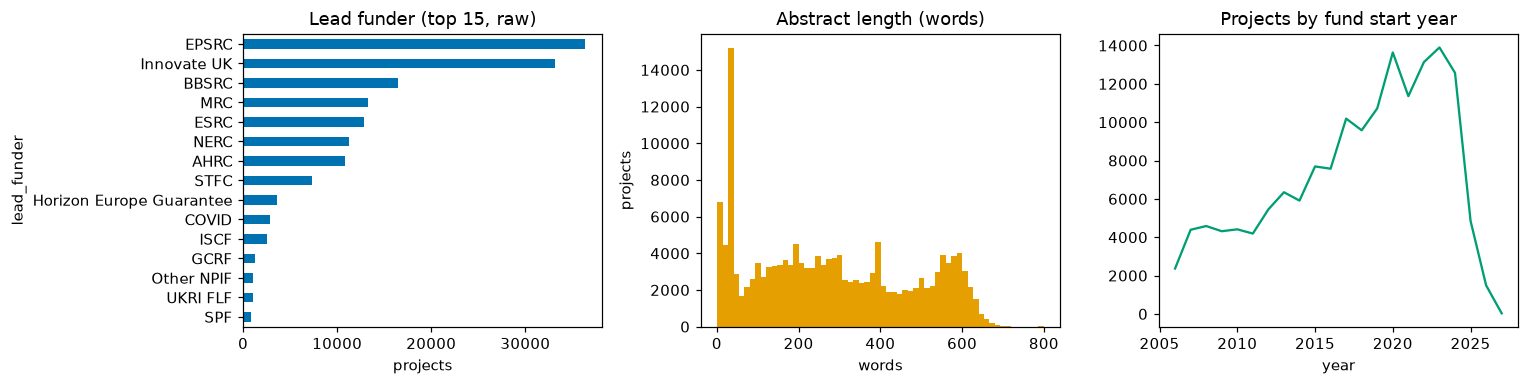

In [5]:
raw["n_words"] = raw.abstract.fillna("").str.split().str.len()
raw["start_year"] = raw.fund_start.dt.year
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
raw.lead_funder.value_counts().head(15)[::-1].plot.barh(ax=ax[0], color=CB[0])
ax[0].set_title("Lead funder (top 15, raw)"); ax[0].set_xlabel("projects")
ax[1].hist(raw.n_words.clip(upper=800), bins=60, color=CB[1]); ax[1].set_title("Abstract length (words)")
ax[1].set_xlabel("words"); ax[1].set_ylabel("projects")
raw.start_year.value_counts().sort_index().loc[1995:2027].plot(ax=ax[2], color=CB[2])
ax[2].set_title("Projects by fund start year"); ax[2].set_xlabel("year")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_overview.png", dpi=150); plt.show()

**Observations.** The raw table mixes the eight councils (EPSRC, ESRC, MRC, BBSRC, AHRC, NERC, STFC and
Innovate UK) with programme budgets (ISCF, GCRF, COVID, Horizon Europe Guarantee …). Those are funding
streams, not councils an applicant can choose, so they are removed below. Many abstracts are placeholders
("Abstracts are not currently available…"), which must be removed, and abstract length is bimodal.

In [6]:
top_repeats = raw.abstract.value_counts().head(12)
pd.DataFrame({"times repeated": top_repeats.values, "abstract (first 110 chars)": [a[:110] for a in top_repeats.index]})

,times repeated,abstract (first 110 chars)
0,12375,Abstracts are not currently available in GtR f...
1,1449,Awaiting Public Project Summary
2,966,no public description
3,758,Doctoral Training Partnerships: a range of pos...
4,515,TBC
5,369,The public description for this project has be...
6,191,tbc
7,96,To be confirmed
8,81,No abstract available.
9,42,MIBTP students undertake a period of training ...


## 3. Cleaning, leakage checks and de-duplication

In [7]:
COUNCILS = ["AHRC", "BBSRC", "EPSRC", "ESRC", "Innovate UK", "MRC", "NERC", "STFC"]
PLACEHOLDER = re.compile(r"(?:abstracts are not currently available|awaiting public project summary|no public description|"
                         r"public description for this project has been requested|^\s*(?:tbc|tba|to be confirmed|n/?a|none|"
                         r"no abstract available\.?)\s*$|doctoral training partnerships: a range of postgraduate)", re.I)

def norm_text(s):
    """Lower-case, strip non-alphanumerics and collapse spaces (used for duplicate keys only)."""
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(s).lower())).strip()

steps = [("raw projects from API", len(raw))]
df = raw[raw.lead_funder.isin(COUNCILS)].copy();                       steps.append(("keep 8 councils (drop programme funders)", len(df)))
df = df[~df.abstract.fillna("").str.contains(PLACEHOLDER)];            steps.append(("drop placeholder abstracts", len(df)))
df = df[df.n_words >= 30];                                             steps.append(("drop abstracts < 30 words", len(df)))
# boilerplate: the same abstract text reused by >= 5 projects with different titles (e.g. centre/CDT text)
df["abs_key"] = df.abstract.map(norm_text)
reuse = df.groupby("abs_key").title.nunique()
df = df[~df.abs_key.isin(reuse[reuse >= 5].index)];                    steps.append(("drop boilerplate reused by >= 5 titles", len(df)))
# exact duplicates (joint grants: one GtR record per partner institution, same title + abstract)
df["dup_key"] = (df.title.map(norm_text) + "||" + df.abs_key).map(lambda s: hashlib.md5(s.encode()).hexdigest())
conflict = df.groupby("dup_key").lead_funder.nunique()
df = df[~df.dup_key.isin(conflict[conflict > 1].index)];               steps.append(("drop duplicates with conflicting funders", len(df)))
dups = df.dup_key.duplicated()
# keep the copy with the largest award as the representative record (sum would double count partners)
df = df.sort_values("award_gbp", ascending=False, kind="stable").drop_duplicates("dup_key"); steps.append(("drop exact duplicates (joint grants)", len(df)))
clean_table = pd.DataFrame(steps, columns=["step", "rows left"])
clean_table["removed"] = (-clean_table["rows left"].diff()).fillna(0).astype(int)
del raw; import gc; gc.collect()   # free ~1 GB: only the cleaned table is needed from here on
clean_table

,step,rows left,removed
0,raw projects from API,158710,0
1,keep 8 councils (drop programme funders),141538,17172
2,drop placeholder abstracts,125815,15723
3,drop abstracts < 30 words,117986,7829
4,drop boilerplate reused by >= 5 titles,117759,227
5,drop duplicates with conflicting funders,117719,40
6,drop exact duplicates (joint grants),113233,4486


### 3.1 Leakage checks
1. **Funder names inside the text.** Some abstracts say "This EPSRC-funded project…" or "Innovate UK
   KTP". A model would learn the name, not the topic, and a real user's draft will not contain it.
2. **Grant category and reference.** `grantCategory` almost reveals the funder (e.g. "Collaborative R&D"
   is only Innovate UK) and the grant reference prefix (EP/, BB/, MR/…) encodes it. Neither is used as a
   feature; the model sees only title + abstract.
3. **Near duplicates across the split.** Joint grants and renewals reuse the same title or abstract with
   small edits. We build groups (same normalised title OR same abstract opening) and split by group so
   copies never sit on both sides of the train/test boundary.

In [8]:
FUNDER_TERMS = [r"engineering and physical sciences research council", r"biotechnology and biological sciences research council",
    r"economic and social research council", r"medical research council", r"arts and humanities research council",
    r"natural environment research council", r"science and technology facilities council", r"innovate ?uk",
    r"technology strategy board", r"uk research and innovation", r"research councils? uk",
    r"epsrc", r"bbsrc", r"esrc", r"mrc", r"ahrc", r"nerc", r"stfc", r"ukri", r"rcuk", r"ktp",
    r"knowledge transfer partnerships?"]
FUNDER_RE = re.compile(r"\b(?:" + "|".join(FUNDER_TERMS) + r")\b", re.I)

def mask_funders(text):
    """Replace any funder / funder-exclusive scheme name with a neutral token."""
    return FUNDER_RE.sub(" funderx ", text)

df["text_raw"] = df.title.fillna("") + ". " + df.abstract.fillna("")
df["text"] = df.text_raw.map(mask_funders)
df["mentions_funder"] = df.text_raw.str.contains(FUNDER_RE)
print("Share of texts naming a funder, by council:")
print(df.groupby("lead_funder").mentions_funder.mean().round(3).to_string())
print("\nOverall:", round(df.mentions_funder.mean(), 3))

Share of texts naming a funder, by council:
lead_funder
AHRC           0.098
BBSRC          0.102
EPSRC          0.144
ESRC           0.095
Innovate UK    0.074
MRC            0.078
NERC           0.148
STFC           0.145

Overall: 0.11


In [9]:
ct = pd.crosstab(df.grant_category, df.lead_funder)
purity = (ct.max(axis=1) / ct.sum(axis=1)).rename("share of top funder")
print("Grant categories with >= 300 projects and how strongly each points to a single funder:")
pd.concat([ct.sum(axis=1).rename("n"), ct.idxmax(axis=1).rename("top funder"), purity.round(3)], axis=1).query("n >= 300").sort_values("n", ascending=False)

Grant categories with >= 300 projects and how strongly each points to a single funder:


,n,top funder,share of top funder
grant_category,,,
Research Grant,42425,EPSRC,0.320
Studentship,38856,EPSRC,0.420
Collaborative R&D,9743,Innovate UK,1.000
Fellowship,6111,MRC,0.286
Feasibility Studies,4099,Innovate UK,1.000
Vouchers,2259,Innovate UK,1.000
Knowledge Transfer Partnership,1481,Innovate UK,1.000
Grant for R&D,1267,Innovate UK,1.000
Research and Innovation,1044,BBSRC,0.243


In [10]:
# Group-aware split keys: union-find over "same normalised title" and "same first 25 words of abstract"
parent = {}
def find(x):
    while parent.setdefault(x, x) != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    parent[find(a)] = find(b)
df = df.reset_index(drop=True)
title_key = "T:" + df.title.map(norm_text)
abs_key = "A:" + df.abs_key.str.split().str[:25].str.join(" ")
for i, (t, a) in enumerate(zip(title_key, abs_key)):
    union(f"R{i}", t); union(f"R{i}", a)
df["group"] = [find(f"R{i}") for i in range(len(df))]
gs = df.group.value_counts()
print(f"{len(df)} projects in {df.group.nunique()} groups; {int((gs > 1).sum())} groups hold "
      f"{int(gs[gs > 1].sum())} near-duplicate projects (renewals, re-used titles, shared abstracts)")
print(df.lead_funder.value_counts().to_string())

113233 projects in 109104 groups; 3148 groups hold 7277 near-duplicate projects (renewals, re-used titles, shared abstracts)
lead_funder
EPSRC          31270
Innovate UK    24544
BBSRC          12809
MRC            10465
AHRC           10306
ESRC            9554
NERC            8774
STFC            5511


## 4. Train/test split (group-aware, stratified) and a time-based check
`StratifiedGroupKFold` keeps every group on one side and keeps council proportions similar. One fold
(20 %) is the untouched test set; hyper-parameters are tuned with 3-fold group CV inside the training set.

In [11]:
le = LabelEncoder().fit(COUNCILS)
y_all = le.transform(df.lead_funder)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(df, y_all, groups=df.group))
assert not set(df.group.iloc[train_idx]) & set(df.group.iloc[test_idx])
df["split"] = "train"; df.loc[test_idx, "split"] = "test"
tr, te = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
y_tr, y_te = le.transform(tr.lead_funder), le.transform(te.lead_funder)
print("train", len(tr), "| test", len(te), "| shared groups:", len(set(tr.group) & set(te.group)))
pd.concat([tr.lead_funder.value_counts(normalize=True).rename("train"),
           te.lead_funder.value_counts(normalize=True).rename("test")], axis=1).round(3)

train 90585 | test 22648 | shared groups: 0


,train,test
lead_funder,,
EPSRC,0.276,0.276
Innovate UK,0.217,0.217
BBSRC,0.113,0.113
MRC,0.092,0.092
AHRC,0.091,0.091
ESRC,0.084,0.084
NERC,0.077,0.077
STFC,0.049,0.049


## 5. Features
* **Text:** title + ". " + abstract, funder names masked (Section 3.1).
* **TF-IDF:** word uni- and bi-grams, `min_df=3`, `max_df=0.5`, sublinear tf, English stop words,
  at most 200,000 features. Sparse, fast and a strong classic baseline for topic classification.
* **Sentence embeddings:** `all-MiniLM-L6-v2` (384-d, 22.7 M parameters) and `BAAI/bge-small-en-v1.5`
  (384-d, 33.4 M parameters), first 256 word-pieces, L2-normalised. These are pre-trained transformers
  (Reimers & Gurevych 2019; Xiao et al. 2023) that map text with similar meaning to nearby vectors, so they
  serve both the classifier and the similar-project search. Embeddings are cached to `.npy`.

In [12]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.5, sublinear_tf=True, stop_words="english",
                        max_features=200_000, dtype=np.float32)
t0 = time.time()
X_tr_tfidf = tfidf.fit_transform(tr.text); X_te_tfidf = tfidf.transform(te.text)
print("TF-IDF", X_tr_tfidf.shape, f"{time.time()-t0:.1f}s")

TF-IDF (90585, 200000) 56.5s


In [13]:
from sentence_transformers import SentenceTransformer
import torch
torch.manual_seed(SEED); torch.set_num_threads(os.cpu_count())
EMB_MODELS = {"minilm": "sentence-transformers/all-MiniLM-L6-v2", "bge": "BAAI/bge-small-en-v1.5"}

def embed_all(key, texts, ids, chunk=5000):
    """Encode texts with a sentence-transformer (L2-normalised float32). Work is saved in chunks of 5,000
    under data/processed/emb_parts/ so an interrupted run resumes where it stopped."""
    path = f"{PROC}/emb_{key}.npy"; idp = f"{PROC}/emb_{key}_ids.json"
    ids, texts = list(ids), list(texts)
    if os.path.exists(path) and json.load(open(idp)) == ids:
        return np.load(path)
    part_dir = f"{PROC}/emb_parts"; os.makedirs(part_dir, exist_ok=True)
    m = None; parts = []; t0 = time.time()
    for i in range(0, len(texts), chunk):
        h = hashlib.md5("".join(ids[i:i+chunk]).encode()).hexdigest()[:12]
        pf = f"{part_dir}/{key}_{i//chunk:03d}_{h}.npy"
        if not os.path.exists(pf):
            if m is None:
                m = SentenceTransformer(EMB_MODELS[key], device="cpu"); m.max_seq_length = 256
            np.save(pf, m.encode(texts[i:i+chunk], batch_size=64, normalize_embeddings=True,
                                 show_progress_bar=False).astype(np.float32))
        parts.append(np.load(pf))
    E = np.vstack(parts)
    print(f"{key}: {len(texts)} texts embedded ({time.time()-t0:.0f}s this run)")
    np.save(path, E); json.dump(ids, open(idp, "w"))
    return E

EMB = {}
for k in EMB_MODELS:
    E = embed_all(k, df.text, df.project_id)
    EMB[k] = (E[train_idx], E[test_idx])
    print(k, E.shape)

minilm (113233, 384)


bge (113233, 384)


## 6. Candidate models and training

| Model | Why it is a candidate |
|---|---|
| Majority class | Floor any useful model must beat |
| TF-IDF + Complement NB | Classic text baseline, designed for imbalanced classes (Rennie et al. 2003) |
| TF-IDF + Logistic Regression | Strong linear model, gives calibrated-ish probabilities the app needs |
| TF-IDF + Linear SVM | Often the best linear text classifier; no native probabilities |
| MiniLM / BGE embeddings + Logistic Regression | Transfer learning: semantic features from a pre-trained transformer |
| BGE embeddings + MLP | Non-linear neural network (one hidden layer) on the same embeddings |
| Ensemble (TF-IDF LR + BGE LR, mean of probabilities) | Combines word-level and semantic evidence |

Imbalance (EPSRC is ~10x STFC) is handled with `class_weight="balanced"`. Hyper-parameters are chosen by
macro-F1 in 3-fold `StratifiedGroupKFold` on the training set only; the test set is used once.

**Why no fine-tuned SciBERT?** The requirements listed a fine-tuned SciBERT (Beltagy et al. 2019) as the
transformer candidate. We did not fine-tune it and report **no** SciBERT score: fine-tuning a 110 M-parameter
model on 90k abstracts needs a GPU (none was available), and serving it needs PyTorch plus ~440 MB of weights,
which alone breaks the ~690 MB Streamlit free tier (Section 9). Instead we test the transformer route with two
frozen sentence encoders (MiniLM, BGE-small; 22-33 M parameters) feeding a linear model and an MLP, which is
the light-weight way a deployed transformer would have to run here.

In [14]:
inner = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(tr, y_tr, groups=tr.group))

def cv_score(make_model, X, y=y_tr):
    """Mean and std of macro-F1 over the 3 inner group folds, plus out-of-fold scores (for the ensemble's CV)."""
    s, oof = [], np.zeros((len(y), len(COUNCILS)))
    for a, b in inner:
        m = make_model().fit(X[a], y[a])
        oof[b] = m.predict_proba(X[b]) if hasattr(m, "predict_proba") else m.decision_function(X[b])
        s.append(f1_score(y[b], oof[b].argmax(1), average="macro"))
    return float(np.mean(s)), float(np.std(s)), oof

def tune(name, make, grid, X):
    """Grid search one hyper-parameter with group CV; return best value and the CV table."""
    rows, oofs = [], {}
    for v in grid:
        t0 = time.time(); mu, sd, oofs[v] = cv_score(lambda: make(v), X)
        rows.append({"model": name, "param": v, "cv_macroF1": round(mu, 4), "cv_sd": round(sd, 4), "sec": round(time.time()-t0, 1)})
    t = pd.DataFrame(rows); best = t.loc[t.cv_macroF1.idxmax()]
    print(t.to_string(index=False)); OOF[name] = oofs[best.param]
    return best.param, best.cv_macroF1, best.cv_sd

TUNING, OOF = {}, {}
TUNING["nb"]   = tune("TF-IDF + ComplementNB (alpha)", lambda a: ComplementNB(alpha=a), [0.1, 0.3, 1.0], X_tr_tfidf)
TUNING["lr"]   = tune("TF-IDF + LogReg (C)", lambda c: LogisticRegression(C=c, class_weight="balanced", max_iter=300), [2.0, 8.0, 32.0], X_tr_tfidf)
TUNING["svm"]  = tune("TF-IDF + LinearSVM (C)", lambda c: LinearSVC(C=c, class_weight="balanced"), [0.1, 0.3, 1.0], X_tr_tfidf)
TUNING["bge_mlp"] = tune("bge + MLP (hidden units)", lambda h: MLPClassifier(hidden_layer_sizes=(int(h),), alpha=1e-4,
    early_stopping=True, validation_fraction=0.1, max_iter=60, random_state=SEED), [256, 1024], EMB["bge"][0])
for k in EMB:
    TUNING[f"{k}_lr"] = tune(f"{k} + LogReg (C)", lambda c: LogisticRegression(C=c, class_weight="balanced", max_iter=2000), [1.0, 4.0, 16.0], EMB[k][0])

                        model  param  cv_macroF1  cv_sd  sec
TF-IDF + ComplementNB (alpha)    0.1      0.8078 0.0010  0.8
TF-IDF + ComplementNB (alpha)    0.3      0.8057 0.0010  0.7
TF-IDF + ComplementNB (alpha)    1.0      0.8022 0.0003  0.7


              model  param  cv_macroF1  cv_sd   sec
TF-IDF + LogReg (C)    2.0      0.8519 0.0009  97.0
TF-IDF + LogReg (C)    8.0      0.8583 0.0004 103.6
TF-IDF + LogReg (C)   32.0      0.8585 0.0018 119.1


                 model  param  cv_macroF1  cv_sd  sec
TF-IDF + LinearSVM (C)    0.1      0.8487 0.0007 11.0
TF-IDF + LinearSVM (C)    0.3      0.8581 0.0009 12.1
TF-IDF + LinearSVM (C)    1.0      0.8599 0.0012 16.2


                   model  param  cv_macroF1  cv_sd   sec
bge + MLP (hidden units)    256      0.8158 0.0002 138.0
bge + MLP (hidden units)   1024      0.8187 0.0018 388.8


              model  param  cv_macroF1  cv_sd  sec
minilm + LogReg (C)    1.0      0.7799 0.0007 38.0
minilm + LogReg (C)    4.0      0.7826 0.0009 51.2
minilm + LogReg (C)   16.0      0.7833 0.0010 71.1


           model  param  cv_macroF1  cv_sd  sec
bge + LogReg (C)    1.0      0.7901 0.0005 32.1
bge + LogReg (C)    4.0      0.7926 0.0013 45.8
bge + LogReg (C)   16.0      0.7925 0.0015 53.0


In [15]:
def evaluate(name, model, X_test, fit_sec, cv=(np.nan, np.nan), proba=None):
    """Test-set metrics. Top-3 uses probabilities, or decision scores for the SVM."""
    t0 = time.time()
    if proba is None:
        proba = model.predict_proba(X_test) if hasattr(model, "predict_proba") else model.decision_function(X_test)
    pred_ms = (time.time() - t0) / X_test.shape[0] * 1000
    pred = proba.argmax(1)
    return {"model": name, "accuracy": accuracy_score(y_te, pred), "macro_F1": f1_score(y_te, pred, average="macro"),
            "weighted_F1": f1_score(y_te, pred, average="weighted"),
            "top3_acc": top_k_accuracy_score(y_te, proba, k=3, labels=range(len(COUNCILS))),
            "cv_macroF1": cv[0], "cv_sd": cv[1], "train_s": fit_sec, "batch_ms_per_doc": pred_ms}, proba, pred

def fit(model, X, y=y_tr):
    t0 = time.time(); model.fit(X, y); return model, time.time() - t0

results, PROBA, FITTED = [], {}, {}
def run(key, name, model, Xtr, Xte, cv=(np.nan, np.nan)):
    m, s = fit(model, Xtr); r, p, _ = evaluate(name, m, Xte, s, cv)
    r["key"] = key; results.append(r); PROBA[key] = p; FITTED[key] = m
    print(f"{name:42s} macro-F1 {r['macro_F1']:.4f}  acc {r['accuracy']:.4f}  top3 {r['top3_acc']:.4f}  ({s:.0f}s)")

run("dummy", "Majority class", DummyClassifier(strategy="prior"), X_tr_tfidf, X_te_tfidf)
run("nb", "TF-IDF + ComplementNB", ComplementNB(alpha=TUNING["nb"][0]), X_tr_tfidf, X_te_tfidf, TUNING["nb"][1:])
run("lr", "TF-IDF + LogReg", LogisticRegression(C=TUNING["lr"][0], class_weight="balanced", max_iter=300), X_tr_tfidf, X_te_tfidf, TUNING["lr"][1:])
run("svm", "TF-IDF + LinearSVM", LinearSVC(C=TUNING["svm"][0], class_weight="balanced"), X_tr_tfidf, X_te_tfidf, TUNING["svm"][1:])
for k in EMB:
    run(f"{k}_lr", f"{k.upper()} emb + LogReg", LogisticRegression(C=TUNING[f'{k}_lr'][0], class_weight="balanced", max_iter=2000),
        EMB[k][0], EMB[k][1], TUNING[f"{k}_lr"][1:])
# MLP: one ReLU hidden layer, Adam, early stopping on a 10 % validation slice of the training set (no test data)
run("bge_mlp", "BGE emb + MLP", MLPClassifier(hidden_layer_sizes=(int(TUNING["bge_mlp"][0]),), alpha=1e-4, early_stopping=True,
    validation_fraction=0.1, max_iter=60, random_state=SEED), EMB["bge"][0], EMB["bge"][1], TUNING["bge_mlp"][1:])
# Ensemble: average the two probability outputs (no extra training)
p_ens = (PROBA["lr"] + PROBA["bge_lr"]) / 2
oof_ens = (OOF["TF-IDF + LogReg (C)"] + OOF["bge + LogReg (C)"]) / 2   # CV score of the ensemble from out-of-fold probabilities
cv_ens = [f1_score(y_tr[b], oof_ens[b].argmax(1), average="macro") for _, b in inner]
r, _, _ = evaluate("Ensemble: TF-IDF LR + BGE LR", None, X_te_tfidf, results[2]["train_s"] + results[5]["train_s"],
                   cv=(np.mean(cv_ens), np.std(cv_ens)), proba=p_ens)
r["key"] = "ens"; results.append(r); PROBA["ens"] = p_ens
res = pd.DataFrame(results).round(4)
res

Majority class                             macro-F1 0.0541  acc 0.2761  top3 0.6060  (0s)


TF-IDF + ComplementNB                      macro-F1 0.8069  acc 0.8088  top3 0.9751  (0s)


TF-IDF + LogReg                            macro-F1 0.8615  acc 0.8693  top3 0.9916  (80s)


TF-IDF + LinearSVM                         macro-F1 0.8622  acc 0.8702  top3 0.9866  (10s)


MINILM emb + LogReg                        macro-F1 0.7835  acc 0.7840  top3 0.9808  (23s)


BGE emb + LogReg                           macro-F1 0.7934  acc 0.7946  top3 0.9824  (21s)


BGE emb + MLP                              macro-F1 0.8197  acc 0.8252  top3 0.9875  (319s)


,model,accuracy,macro_F1,weighted_F1,top3_acc,cv_macroF1,cv_sd,train_s,batch_ms_per_doc,key
0,Majority class,0.2761,0.0541,0.1195,0.6060,NaN,NaN,0.0137,0.0002,dummy
1,TF-IDF + ComplementNB,0.8088,0.8069,0.8093,0.9751,0.8078,0.0010,0.3720,0.0043,nb
2,TF-IDF + LogReg,0.8693,0.8615,0.8697,0.9916,0.8585,0.0018,80.2748,0.0013,lr
3,TF-IDF + LinearSVM,0.8702,0.8622,0.8706,0.9866,0.8599,0.0012,9.8721,0.0016,svm
4,MINILM emb + LogReg,0.7840,0.7835,0.7850,0.9808,0.7833,0.0010,23.1616,0.0013,minilm_lr
5,BGE emb + LogReg,0.7946,0.7934,0.7957,0.9824,0.7926,0.0013,21.0148,0.0015,bge_lr
6,BGE emb + MLP,0.8252,0.8197,0.8254,0.9875,0.8187,0.0018,318.5545,0.0583,bge_mlp
7,Ensemble: TF-IDF LR + BGE LR,0.8644,0.8577,0.8652,0.9916,0.8562,0.0005,101.2896,0.0000,ens


### 6.1 How much did masking matter? (leakage experiment)
Same TF-IDF + LogReg, trained and tested on the **unmasked** text. A higher score here would be inflated by
funder names in the text, which a real user's draft would not contain.

In [16]:
tf_raw = TfidfVectorizer(**tfidf.get_params())
Xr_tr = tf_raw.fit_transform(tr.text_raw); Xr_te = tf_raw.transform(te.text_raw)
m_raw = LogisticRegression(C=TUNING["lr"][0], class_weight="balanced", max_iter=300).fit(Xr_tr, y_tr)
p_raw = m_raw.predict(Xr_te)
leak = pd.DataFrame({"text": ["unmasked (leaky)", "funder names masked (used)"],
    "macro_F1": [f1_score(y_te, p_raw, average="macro"), res.loc[res.model == "TF-IDF + LogReg", "macro_F1"].item()],
    "macro_F1 on test texts that name a funder": [
        f1_score(y_te[te.mentions_funder], p_raw[te.mentions_funder], average="macro"),
        f1_score(y_te[te.mentions_funder], PROBA["lr"].argmax(1)[te.mentions_funder], average="macro")]}).round(4)
leak

,text,macro_F1,macro_F1 on test texts that name a funder
0,unmasked (leaky),0.8663,0.9289
1,funder names masked (used),0.8615,0.8875


### 6.2 Is the data large enough? Learning curve
Macro-F1 on the fixed test set when the training set is sub-sampled (stratified). If the curve is still
rising steeply at 100 %, more data would help; if it flattens, the data is sufficient for these models.

 fraction  n_train  TF-IDF + LogReg  BGE emb + LogReg
     0.02     1807           0.7782            0.7608
     0.05     4525           0.8127            0.7678
     0.10     9054           0.8256            0.7769
     0.25    22643           0.8434            0.7845
     0.50    45290           0.8523            0.7902
     1.00    90585           0.8615            0.7934


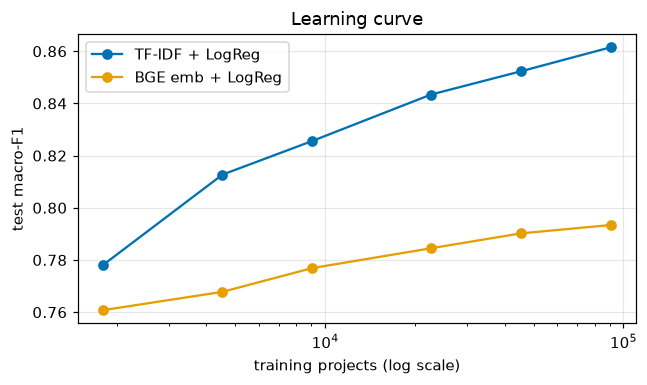

In [17]:
fracs = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]
rng = np.random.RandomState(SEED); lc = []
for f in fracs:
    idx = np.sort(np.concatenate([rng.permutation(np.where(y_tr == c)[0])[:max(5, int(f * (y_tr == c).sum()))]
                                  for c in range(len(COUNCILS))]))
    m1 = LogisticRegression(C=TUNING["lr"][0], class_weight="balanced", max_iter=300).fit(X_tr_tfidf[idx], y_tr[idx])
    m2 = LogisticRegression(C=TUNING["bge_lr"][0], class_weight="balanced", max_iter=2000).fit(EMB["bge"][0][idx], y_tr[idx])
    lc.append({"fraction": f, "n_train": len(idx), "TF-IDF + LogReg": f1_score(y_te, m1.predict(X_te_tfidf), average="macro"),
               "BGE emb + LogReg": f1_score(y_te, m2.predict(EMB["bge"][1]), average="macro")})
lc = pd.DataFrame(lc).round(4); print(lc.to_string(index=False))
ax = lc.plot(x="n_train", y=["TF-IDF + LogReg", "BGE emb + LogReg"], marker="o", logx=True, figsize=(6, 3.6), color=CB[:2])
ax.set_xlabel("training projects (log scale)"); ax.set_ylabel("test macro-F1"); ax.set_title("Learning curve"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG}/learning_curve.png", dpi=150); plt.show()

### 6.3 Time-based check
Train on projects that started before 2021 and test on projects starting 2021 or later (groups that cross
the boundary are dropped). This tests whether the model still works on newer topics, as in real use.

In [18]:
yr = df.start_year
old = df.index[(yr < 2021)]; new = df.index[(yr >= 2021)]
new = new[~df.group.iloc[new].isin(set(df.group.iloc[old]))]
yo, yn = y_all[old], y_all[new]
tf_t = TfidfVectorizer(**tfidf.get_params()); Xo = tf_t.fit_transform(df.text.iloc[old]); Xn = tf_t.transform(df.text.iloc[new])
Eb = np.load(f"{PROC}/emb_bge.npy")
mt1 = LogisticRegression(C=TUNING["lr"][0], class_weight="balanced", max_iter=300).fit(Xo, yo)
mt2 = LogisticRegression(C=TUNING["bge_lr"][0], class_weight="balanced", max_iter=2000).fit(Eb[old], yo)
pt = (mt1.predict_proba(Xn) + mt2.predict_proba(Eb[new])) / 2
temporal = pd.DataFrame({"model": ["TF-IDF + LogReg", "BGE emb + LogReg", "Ensemble"],
    "macro_F1 (train <2021, test >=2021)": [f1_score(yn, mt1.predict(Xn), average="macro"),
        f1_score(yn, mt2.predict(Eb[new]), average="macro"), f1_score(yn, pt.argmax(1), average="macro")]}).round(4)
print(f"old (train) = {len(old)}, new (test) = {len(new)}"); temporal

old (train) = 71714, new (test) = 40958


,model,"macro_F1 (train <2021, test >=2021)"
0,TF-IDF + LogReg,0.8270
1,BGE emb + LogReg,0.7611
2,Ensemble,0.8281


### 6.4 Are the probabilities trustworthy? Calibration (v2)
The app shows probabilities, so they should mean what they say: of all predictions made with 80 %
confidence, about 80 % should be right. We measure the expected calibration error (ECE, 15 bins; Guo et al.
2017), the multi-class Brier score and the log loss on the test set. Class-weighted training tends to distort
confidence, so we fit a single **temperature** T on the out-of-fold training probabilities from Section 6
(never on the test set) and rescale: p ∝ p^(1/T). This changes no prediction, only how confident it is.

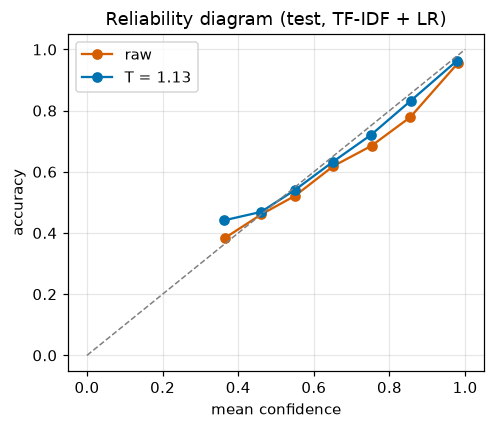

,probabilities,ECE,Brier,log loss,accuracy
0,raw (class-weighted LR),0.0336,0.1954,0.3846,0.8693
1,"temperature-scaled (T = 1.13, fitted on OOF tr...",0.0180,0.1935,0.3755,0.8693


In [19]:
from scipy.optimize import minimize_scalar
def ece(P, y, bins=15):
    """Expected calibration error of the top-class confidence."""
    conf, pred, e = P.max(1), P.argmax(1), 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e
def temp_scale(P, T):
    """Temperature scaling applied to probabilities (equivalent to dividing the log-probabilities by T)."""
    L = np.log(np.clip(P, 1e-12, 1)) / T; L -= L.max(1, keepdims=True); E = np.exp(L)
    return E / E.sum(1, keepdims=True)
def nll(P, y):
    return float(-np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1))))
def brier(P, y):
    return float(np.mean(np.sum((P - np.eye(P.shape[1])[y]) ** 2, axis=1)))

oof_lr = OOF["TF-IDF + LogReg (C)"]
T_LR = float(minimize_scalar(lambda t: nll(temp_scale(oof_lr, t), y_tr), bounds=(0.2, 5), method="bounded").x)
P_raw, P_cal = PROBA["lr"], temp_scale(PROBA["lr"], T_LR)
calib_tab = pd.DataFrame({"probabilities": ["raw (class-weighted LR)", f"temperature-scaled (T = {T_LR:.2f}, fitted on OOF train)"],
    "ECE": [ece(P_raw, y_te), ece(P_cal, y_te)], "Brier": [brier(P_raw, y_te), brier(P_cal, y_te)],
    "log loss": [nll(P_raw, y_te), nll(P_cal, y_te)], "accuracy": [accuracy_score(y_te, P_raw.argmax(1)), accuracy_score(y_te, P_cal.argmax(1))]}).round(4)
fig, ax = plt.subplots(figsize=(4.6, 4))
for P, lab, c in [(P_raw, "raw", CB[3]), (P_cal, f"T = {T_LR:.2f}", CB[0])]:
    conf, cor = P.max(1), P.argmax(1) == y_te; edges = np.linspace(0, 1, 11); mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 20: mids.append(conf[m].mean()); accs.append(cor[m].mean())
    ax.plot(mids, accs, "o-", color=c, label=lab)
ax.plot([0, 1], [0, 1], "--", c="grey", lw=1); ax.set_xlabel("mean confidence"); ax.set_ylabel("accuracy")
ax.set_title("Reliability diagram (test, TF-IDF + LR)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG}/reliability.png", dpi=150); plt.show()
calib_tab

### 6.5 Does it transfer to other countries? Cross-country test (v2)
Following the idea of mapping one funder's projects into another funder's structure (Khor et al. 2018),
we apply the UK model, unchanged, to grant abstracts collected with `collect_international.py` from the
NSF Awards API and NIH RePORTER API (USA, awards from 2023) and the ARC Grants API (Australia, the 2,000
most recent grants). The expected UK council comes from the foreign funder's structure: NSF BIO→BBSRC, GEO→NERC, SBE→ESRC, ENG and CISE→EPSRC, MPS chemistry, materials and
mathematics (codes CHE, DMR/MRS, DMS/MMS)→EPSRC, MPS astronomy→STFC, TIP (technology and innovation)→Innovate UK; NIH→MRC; ARC by
primary field of research (e.g. 31 biology→BBSRC, 36/43/47/50 arts and humanities→AHRC, 40 engineering→EPSRC,
5101 astronomy→STFC, see `ARC_MAP`). Physics outside astronomy (split between EPSRC and STFC in the UK) and
fields with no clear UK council (e.g. built environment, law, psychology) are left out. This is a hard,
out-of-distribution test: different vocabulary, US spelling and different funding boundaries.

In [20]:
from collect_international import OUT as INTL
NSF_MAP = {"BIO": "BBSRC", "GEO": "NERC", "SBE": "ESRC", "ENG": "EPSRC", "CISE": "EPSRC", "TIP": "Innovate UK"}
NSF_DIV = {"AST": "STFC", "CHE": "EPSRC", "DMR": "EPSRC", "MRS": "EPSRC", "DMS": "EPSRC", "MMS": "EPSRC"}  # MRS/MMS = current codes for materials / mathematics
US_MASK = re.compile(r"\b(?:nsf|nih|national science foundation|national institutes? of health|nsf's)\b", re.I)
NSF_BOILER = re.compile(r"This award reflects NSF's statutory mission.*$", re.S)
rows = []
for f in sorted(glob.glob(f"{INTL}/nsf_*.json.gz")):
    for a in json.load(gzip.open(f, "rt")):
        exp = NSF_DIV.get(a.get("divAbbr")) if a.get("dirAbbr") == "MPS" else NSF_MAP.get(a.get("dirAbbr"))
        rows.append({"source": "NSF", "unit": f"{a.get('dirAbbr')}/{a.get('divAbbr')}", "expected": exp,
                     "text": f"{a.get('title') or ''}. {NSF_BOILER.sub('', a.get('abstractText') or '')}"})
ARC_MAP = {"30": "BBSRC", "31": "BBSRC", "32": "MRC", "34": "EPSRC", "35": "ESRC", "36": "AHRC", "37": "NERC", "38": "ESRC",
           "39": "ESRC", "40": "EPSRC", "41": "NERC", "42": "MRC", "43": "AHRC", "44": "ESRC", "46": "EPSRC", "47": "AHRC",
           "49": "EPSRC", "50": "AHRC", "5101": "STFC", "5107": "STFC"}   # ANZSRC 2020 fields of research
ARC_RE = re.compile(r"\b(?:ARC|Australian Research Council)\b")
for f in sorted(glob.glob(f"{INTL}/arc_*.json.gz")):
    for a in json.load(gzip.open(f, "rt")):
        fld = (a.get("field") or "")[:4]
        rows.append({"source": "ARC", "unit": f"ARC/{fld[:2]}", "expected": ARC_MAP.get(fld, ARC_MAP.get(fld[:2])),
                     "text": ARC_RE.sub(" funderx ", a.get("summary") or "")})
for f in sorted(glob.glob(f"{INTL}/nih_*.json.gz")):
    for a in json.load(gzip.open(f, "rt")):
        rows.append({"source": "NIH", "unit": f"NIH/{a.get('institute')}", "expected": "MRC",
                     "text": f"{a.get('title') or ''}. {a.get('abstractText') or ''}"})
intl = pd.DataFrame(rows)
n0 = len(intl)
intl = intl[intl.expected.notna()].drop_duplicates("text")
intl["text"] = intl.text.map(lambda t: US_MASK.sub(" funderx ", mask_funders(t)))
intl = intl[intl.text.str.split().str.len() >= 30].reset_index(drop=True)
print(f"collected {n0} US and Australian awards; {len(intl)} usable after mapping, de-duplication and the 30-word rule")
print(intl.groupby(["source", "expected"]).size().to_string())
yi = le.transform(intl.expected)
Pi_lr = temp_scale(FITTED["lr"].predict_proba(tfidf.transform(intl.text)), T_LR)
enc_b = SentenceTransformer(EMB_MODELS["bge"], device="cpu"); enc_b.max_seq_length = 256
Ei = enc_b.encode(intl.text.tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
Pi_bge = FITTED["bge_lr"].predict_proba(Ei)
cc = []
for name, P in [("TF-IDF + LogReg", Pi_lr), ("BGE emb + LogReg", Pi_bge), ("Ensemble", (Pi_lr + Pi_bge) / 2)]:
    cc.append({"model": name, "accuracy": accuracy_score(yi, P.argmax(1)), "macro_F1": f1_score(yi, P.argmax(1), average="macro", labels=np.unique(yi)),
               "top3_acc": top_k_accuracy_score(yi, P, k=3, labels=range(len(COUNCILS)))})
cross = pd.DataFrame(cc).round(3)
intl["pred"] = le.inverse_transform(Pi_lr.argmax(1))
by_src = pd.DataFrame([{"source": s_, "n": int(m_.sum()), "TF-IDF LR acc": accuracy_score(yi[m_], Pi_lr[m_].argmax(1)),
    "BGE LR acc": accuracy_score(yi[m_], Pi_bge[m_].argmax(1)), "TF-IDF LR top3": top_k_accuracy_score(yi[m_], Pi_lr[m_], k=3, labels=range(len(COUNCILS)))}
    for s_, m_ in [(s_, (intl.source == s_).values) for s_ in ["NSF", "NIH", "ARC"]]]).round(3)
print(by_src.to_string(index=False))
print("\nTF-IDF + LR, share of foreign awards per expected council that got that council:")
print(intl.assign(ok=intl.pred == intl.expected).groupby("expected").ok.agg(["mean", "size"]).round(3).to_string())
print("\nWhat NIH projects were predicted as:", intl[intl.source == "NIH"].pred.value_counts(normalize=True).round(3).to_dict())
cross

collected 5000 US and Australian awards; 3852 usable after mapping, de-duplication and the 30-word rule
source  expected   
ARC     AHRC           155
        BBSRC          303
        EPSRC          784
        ESRC           238
        MRC             86
        NERC           137
        STFC            41
NIH     MRC            940
NSF     BBSRC          126
        EPSRC          664
        ESRC            49
        Innovate UK    159
        NERC           158
        STFC            12


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

source    n  TF-IDF LR acc  BGE LR acc  TF-IDF LR top3
   NSF 1168          0.753       0.718           0.956
   NIH  940          0.706       0.706           0.965
   ARC 1744          0.596       0.640           0.935

TF-IDF + LR, share of foreign awards per expected council that got that council:
              mean  size
expected                
AHRC         0.626   155
BBSRC        0.476   429
EPSRC        0.741  1448
ESRC         0.662   287
Innovate UK  0.472   159
MRC          0.665  1026
NERC         0.719   295
STFC         0.943    53

What NIH projects were predicted as: {'MRC': 0.706, 'BBSRC': 0.143, 'EPSRC': 0.069, 'ESRC': 0.054, 'Innovate UK': 0.017, 'NERC': 0.006, 'AHRC': 0.003, 'STFC': 0.001}


,model,accuracy,macro_F1,top3_acc
0,TF-IDF + LogReg,0.671,0.623,0.949
1,BGE emb + LogReg,0.680,0.617,0.959
2,Ensemble,0.697,0.649,0.962


## 7. Similar-project search and typical award range
For every test project we search the **training** projects (cosine similarity) and check whether the
10 neighbours are on-topic. GtR has no relevance labels, so we use two proxies: the neighbour has the same
council, and the neighbour shares at least one GtR research topic (for projects that have topics).
The award range is a percentile band of the neighbours' awards (30 neighbours; optionally only neighbours
of the same scheme, which the app lets the user pick). We measure how often the real award falls inside the
band and how wide it is, against a council-wide band that even "knows" the true council.

In [21]:
def topk_dense(Q, D, k=10, bs=2048):
    """Exact top-k cosine search (vectors are L2-normalised, so dot product = cosine)."""
    out = np.empty((len(Q), k), dtype=np.int64)
    for i in range(0, len(Q), bs):
        S = Q[i:i+bs] @ D.T; out[i:i+bs] = np.argpartition(-S, k, axis=1)[:, :k]
    return out

def topk_sparse(Q, D, k=10, bs=1024):
    out = np.empty((Q.shape[0], k), dtype=np.int64)
    for i in range(0, Q.shape[0], bs):
        S = (Q[i:i+bs] @ D.T).toarray(); out[i:i+bs] = np.argpartition(-S, k, axis=1)[:, :k]
    return out

rng = np.random.RandomState(SEED); q = rng.choice(len(te), size=min(3000, len(te)), replace=False)
tr_topics = tr.research_topics.fillna("").str.split("; ").map(lambda l: set(x for x in l if x))
te_topics = te.research_topics.fillna("").str.split("; ").map(lambda l: set(x for x in l if x))
NB = {"TF-IDF cosine": topk_sparse(X_te_tfidf[q], X_tr_tfidf),
      "MiniLM cosine": topk_dense(EMB["minilm"][1][q], EMB["minilm"][0]),
      "BGE cosine": topk_dense(EMB["bge"][1][q], EMB["bge"][0])}
ret = []
for name, nb in NB.items():
    same_f = (y_tr[nb] == y_te[q][:, None]).mean()
    has_t = np.array([len(te_topics.iloc[i]) > 0 for i in q])
    topic = np.mean([np.mean([len(te_topics.iloc[i] & tr_topics.iloc[j]) > 0 for j in row]) for i, row in zip(q[has_t], nb[has_t])])
    ret.append({"retriever": name, "P@10 same council": same_f, "P@10 shares a research topic": topic})
ret = pd.DataFrame(ret).round(4); ret

,retriever,P@10 same council,P@10 shares a research topic
0,TF-IDF cosine,0.7021,0.3502
1,MiniLM cosine,0.6929,0.3458
2,BGE cosine,0.6923,0.3302


In [22]:
# Award range: compare neighbour-based ranges with a council-wide baseline. In the app the user may also
# choose the scheme (e.g. Research Grant, Studentship), so we test neighbours restricted to the same scheme.
def pct(a, qs):
    a = np.where(a > 0, a, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return [np.nanpercentile(a, x, axis=1) for x in qs]
amt_tr = tr.award_gbp.values
qa = q[(te.award_gbp.iloc[q].fillna(0).values > 0)]
true = te.award_gbp.values[qa]
cat_tr, cat_q = tr.grant_category.values, te.grant_category.values[qa]
fq = tr[tr.award_gbp > 0].groupby("lead_funder").award_gbp
rows = []
def add(name, lo, med, hi):
    rows.append({"method": name, "coverage of true award": np.mean((true >= lo) & (true <= hi)),
                 "median |log10 error| of median": np.nanmedian(np.abs(np.log10(med) - np.log10(true))),
                 "median width (hi/lo)": np.nanmedian(hi / lo)})
for rname, Q, D, search in [("TF-IDF", X_te_tfidf[qa], X_tr_tfidf, topk_sparse), ("BGE", EMB["bge"][1][qa], EMB["bge"][0], topk_dense)]:
    nb30 = search(Q, D, k=30)
    S = np.vstack([np.asarray((Q[i] @ D[nb30[i]].T).todense()).ravel() if rname == "TF-IDF" else D[nb30[i]] @ Q[i]
                   for i in range(len(qa))])
    nb30 = np.take_along_axis(nb30, np.argsort(-S, axis=1), axis=1)     # sort the 30 by similarity
    nb_cat = nb30.copy()                                                 # same-scheme neighbours
    for c in np.unique(cat_q):
        rc = np.where(cat_q == c)[0]; pool = np.where(cat_tr == c)[0]
        if len(pool) >= 30:
            nb_cat[rc] = pool[search(Q[rc], D[pool], k=30)]
    add(f"{rname}: 10 neighbours, P25-P75", *pct(amt_tr[nb30[:, :10]], [25, 50, 75]))
    add(f"{rname}: 30 neighbours, P25-P75", *pct(amt_tr[nb30], [25, 50, 75]))
    add(f"{rname}: 30 neighbours, P10-P90", *pct(amt_tr[nb30], [10, 50, 90]))
    add(f"{rname}: 30 same-scheme neighbours, P25-P75", *pct(amt_tr[nb_cat], [25, 50, 75]))
    add(f"{rname}: 30 same-scheme neighbours, P10-P90", *pct(amt_tr[nb_cat], [10, 50, 90]))
for lo_q, hi_q in [(.25, .75), (.10, .90)]:
    bq = fq.quantile([lo_q, .5, hi_q]).unstack().loc[te.lead_funder.values[qa]].values
    add(f"council-wide P{int(lo_q*100)}-P{int(hi_q*100)} (oracle: true council)", bq[:, 0], bq[:, 1], bq[:, 2])
award = pd.DataFrame(rows).round(3)
print("test queries with an award:", len(qa)); award

test queries with an award: 1986


,method,coverage of true award,median |log10 error| of median,median width (hi/lo)
0,"TF-IDF: 10 neighbours, P25-P75",0.435,0.254,2.774
1,"TF-IDF: 30 neighbours, P25-P75",0.522,0.247,3.781
2,"TF-IDF: 30 neighbours, P10-P90",0.801,0.247,12.952
3,"TF-IDF: 30 same-scheme neighbours, P25-P75",0.520,0.185,2.967
4,"TF-IDF: 30 same-scheme neighbours, P10-P90",0.797,0.185,9.017
5,"BGE: 10 neighbours, P25-P75",0.392,0.284,2.825
6,"BGE: 30 neighbours, P25-P75",0.467,0.272,3.817
7,"BGE: 30 neighbours, P10-P90",0.752,0.272,12.457
8,"BGE: 30 same-scheme neighbours, P25-P75",0.504,0.204,3.069
9,"BGE: 30 same-scheme neighbours, P10-P90",0.786,0.204,9.123


### 7.1 Hybrid lexical + dense search (v2)
Hybrid search often beats either signal alone (e.g. reciprocal rank fusion, Cormack et al. 2009). We fuse the
top-50 TF-IDF and top-50 BGE neighbours with RRF (k = 60) and evaluate on the same queries and proxies.

In [23]:
def rrf(lists, k=60, top=10):
    """Reciprocal rank fusion of several ranked lists of document ids."""
    out = []
    for ranks in zip(*lists):
        sc = {}
        for r in ranks:
            for pos, doc in enumerate(r):
                sc[doc] = sc.get(doc, 0) + 1 / (k + pos + 1)
        out.append(sorted(sc, key=sc.get, reverse=True)[:top])
    return np.array(out)
def ranked(Q, D, k, dense):
    """Top-k ids sorted by similarity (dense: numpy array, sparse: TF-IDF)."""
    S = (Q @ D.T) if dense else (Q @ D.T).toarray()
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    return np.take_along_axis(idx, np.argsort(-np.take_along_axis(S, idx, axis=1), axis=1), axis=1)
L_tf = np.vstack([ranked(X_te_tfidf[q[i:i+500]], X_tr_tfidf, 50, False) for i in range(0, len(q), 500)])
L_bge = np.vstack([ranked(EMB["bge"][1][q[i:i+500]], EMB["bge"][0], 50, True) for i in range(0, len(q), 500)])
NB2 = {"TF-IDF cosine": L_tf[:, :10], "BGE cosine": L_bge[:, :10], "Hybrid RRF (TF-IDF + BGE)": rrf([L_tf, L_bge])}
ret2 = []
has_t = np.array([len(te_topics.iloc[i]) > 0 for i in q])
for name, nb in NB2.items():
    topic = np.mean([np.mean([len(te_topics.iloc[i] & tr_topics.iloc[j]) > 0 for j in row]) for i, row in zip(q[has_t], nb[has_t])])
    ret2.append({"retriever": name, "P@10 same council": (y_tr[nb] == y_te[q][:, None]).mean(), "P@10 shares a research topic": topic})
ret2 = pd.DataFrame(ret2).round(4); ret2

,retriever,P@10 same council,P@10 shares a research topic
0,TF-IDF cosine,0.7021,0.3502
1,BGE cosine,0.6923,0.3302
2,Hybrid RRF (TF-IDF + BGE),0.7112,0.3612


### 7.2 Retrieval metrics: Recall@10 and MRR (v3)
Two label sources. **(a) Known-item search:** 5,000 test projects form a corpus of abstracts *without titles*;
2,000 of their titles are the queries and the relevant document is the project's own abstract (exactly one
relevant item, so Recall@10 = share of queries whose abstract is in the top 10, and MRR@10 = mean of 1/rank).
**(b) Topic pseudo-labels:** on the Section 7 queries, a neighbour is relevant if it shares a GtR research topic;
Hit@10 = share of queries with at least one relevant neighbour in the top 10 and MRR@10 = 1/rank of the first.
Exact (brute-force) cosine search is used: at 113k documents it takes ~50 ms per query, so an approximate
index such as FAISS would only add a dependency without a speed need (Section 9).

In [24]:
rng = np.random.RandomState(SEED)
corp = rng.choice(len(te), min(5000, len(te)), replace=False); nq = min(2000, len(corp)); qs = corp[:nq]
docs = te.abstract.iloc[corp].fillna("").map(mask_funders).tolist()
queries = te.title.iloc[qs].fillna("").map(mask_funders).tolist()
def rank_metrics(S, k=10):
    """S: queries x corpus similarity; the relevant item of query i is corpus item i."""
    s_true = S[np.arange(S.shape[0]), np.arange(S.shape[0])]
    rank = (S > s_true[:, None]).sum(1) + 1
    return {"Recall@10": float(np.mean(rank <= k)), "MRR@10": float(np.mean(np.where(rank <= k, 1 / rank, 0)))}
known = {}
Dq, Qq = tfidf.transform(docs), tfidf.transform(queries)
S_tf = (Qq @ Dq.T).toarray(); known["TF-IDF cosine"] = rank_metrics(S_tf)
S_dense = {}
for key in ["minilm", "bge"]:
    enc = SentenceTransformer(EMB_MODELS[key], device="cpu"); enc.max_seq_length = 256
    pre = "Represent this sentence for searching relevant passages: " if key == "bge" else ""   # BGE's query instruction
    Ed = enc.encode(docs, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    Eq = enc.encode([pre + t for t in queries], batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    S_dense[key] = Eq @ Ed.T; known[f"{key.upper()} cosine"] = rank_metrics(S_dense[key])
def rrf_scores(*Ss, k=60):
    """Reciprocal rank fusion of full similarity matrices."""
    out = np.zeros_like(Ss[0])
    for S in Ss:
        out += 1 / (k + np.argsort(np.argsort(-S, axis=1), axis=1) + 1)
    return out
known["Hybrid RRF (TF-IDF + BGE)"] = rank_metrics(rrf_scores(S_tf, S_dense["bge"]))
del S_tf, S_dense
def topic_metrics(ranked_lists):
    hit, rr = [], []
    for i, row in zip(q[has_t], ranked_lists[has_t]):
        rel = [len(te_topics.iloc[i] & tr_topics.iloc[j]) > 0 for j in row[:10]]
        hit.append(any(rel)); rr.append(1 / (rel.index(True) + 1) if any(rel) else 0)
    return {"Hit@10 (topic)": float(np.mean(hit)), "MRR@10 (topic)": float(np.mean(rr))}
L_mini = np.vstack([ranked(EMB["minilm"][1][q[i:i+500]], EMB["minilm"][0], 10, True) for i in range(0, len(q), 500)])
topic = {"TF-IDF cosine": topic_metrics(L_tf), "MINILM cosine": topic_metrics(L_mini), "BGE cosine": topic_metrics(L_bge),
         "Hybrid RRF (TF-IDF + BGE)": topic_metrics(NB2["Hybrid RRF (TF-IDF + BGE)"])}
retr_metrics = pd.DataFrame([{"retriever": k, **known[k], **topic[k]} for k in known]).round(4)
print(f"known-item: {nq} title queries against {len(corp)} test abstracts; topic labels: {int(has_t.sum())} queries")
retr_metrics

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

known-item: 2000 title queries against 5000 test abstracts; topic labels: 1010 queries


,retriever,Recall@10,MRR@10,Hit@10 (topic),MRR@10 (topic)
0,TF-IDF cosine,0.8950,0.7727,0.8713,0.5788
1,MINILM cosine,0.9000,0.7998,0.8673,0.5663
2,BGE cosine,0.8945,0.7979,0.8554,0.5518
3,Hybrid RRF (TF-IDF + BGE),0.9210,0.8203,0.8812,0.5936


**Structured 50-query relevance sheet.** The requirements asked for ~50 queries judged by hand. Below, 50 random
test projects and the top-3 TF-IDF matches are listed with automatic checks (same council, shared topic, same
scheme). The sheet is saved to `models/manual_relevance_sheet.csv` with an empty `relevant (group)` column for
the group's own judgements; the automatic columns are proxies, **not** human judgements.

In [25]:
q50 = q[:50]
sheet = []
for i, row in zip(q50, L_tf[:50, :3]):
    for r, j in enumerate(row, 1):
        sheet.append({"query_title": te.title.iloc[i], "rank": r, "match_title": tr.title.iloc[j], "query_council": te.lead_funder.iloc[i],
                      "match_council": tr.lead_funder.iloc[j], "same council": te.lead_funder.iloc[i] == tr.lead_funder.iloc[j],
                      "shares topic": len(te_topics.iloc[i] & tr_topics.iloc[j]) > 0 if te_topics.iloc[i] else None,
                      "same scheme": te.grant_category.iloc[i] == tr.grant_category.iloc[j], "relevant (group)": ""})
sheet = pd.DataFrame(sheet); sheet.to_csv(f"{MODELS}/manual_relevance_sheet.csv", index=False)
print(sheet[["same council", "same scheme"]].mean().round(3).to_dict(), "| shares topic (where topics exist):",
      round(sheet["shares topic"].dropna().astype(float).mean(), 3))
sheet.head(9)[["query_title", "rank", "match_title", "query_council", "match_council"]]

{'same council': 0.707, 'same scheme': 0.593} | shares topic (where topics exist): 0.444


,query_title,rank,match_title,query_council,match_council
0,Investigating deliberative methods for setting...,1,Measuring and valuing the broader patient bene...,MRC,MRC
1,Investigating deliberative methods for setting...,2,Going beyond health related quality of life - ...,MRC,MRC
2,Investigating deliberative methods for setting...,3,Is &quot;end-of-life&quot; care more valuable?...,MRC,MRC
3,Social and Occupational Contact Patterns and R...,1,Winter respiratory risk prediction model in ad...,MRC,MRC
4,Social and Occupational Contact Patterns and R...,2,Quantifying the structure of transmission netw...,MRC,MRC
5,Social and Occupational Contact Patterns and R...,3,Advanced Statistical Methods for Infectious Di...,MRC,EPSRC
6,Tomographic Imaging: UK Collaborative Computat...,1,Large Field X-ray Tomographic Imaging,EPSRC,STFC
7,Tomographic Imaging: UK Collaborative Computat...,2,A Reconstruction Toolkit for Multichannel CT,EPSRC,EPSRC
8,Tomographic Imaging: UK Collaborative Computat...,3,Low-dose low-cost 3D X-ray imaging for reducti...,EPSRC,Innovate UK


### 7.3 Award amount: Ridge vs LightGBM on log amount, against the neighbour band (v3)
The requirements asked to compare Ridge with LightGBM on log(1 + award) and to check range coverage on the test
set. Same train/test split as above; only projects with a positive award. Two feature settings:
* **text only** (what the app always has): TF-IDF for Ridge; BGE embeddings for LightGBM (trees need dense input);
* **text + metadata a user knows** (council, scheme, duration, start year).
Ranges: LightGBM quantile models (alpha 0.25/0.75 and 0.10/0.90) against the P25–P75 / P10–P90 band of the 30
nearest TF-IDF neighbours (the deployed method). Metrics: MAE on natural-log amount, median absolute error in £,
coverage of the true award and median band width (hi/lo).

In [26]:
import scipy.sparse as sp
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder
import lightgbm as lgb
def award_frame(d):
    dur = ((d.fund_end - d.fund_start).dt.days / 365.25).clip(0, 10)
    ok = (d.award_gbp > 0) & dur.notna() & d.fund_start.notna()
    return ok.values, dur.fillna(0).values, d.fund_start.dt.year.fillna(2015).values
ok_tr, dur_tr, yr_tr = award_frame(tr); ok_te, dur_te, yr_te = award_frame(te)
ya_tr, ya_te = np.log1p(tr.award_gbp.values[ok_tr]), np.log1p(te.award_gbp.values[ok_te])
top_cats = tr.grant_category.value_counts().index[:30]
ohe = OneHotEncoder(handle_unknown="ignore").fit(pd.DataFrame({"c": tr.lead_funder, "g": tr.grant_category.where(tr.grant_category.isin(top_cats), "other")}))
def meta_sparse(d, ok, dur, yr):
    cats = ohe.transform(pd.DataFrame({"c": d.lead_funder, "g": d.grant_category.where(d.grant_category.isin(top_cats), "other")}))[ok]
    num = sp.csr_matrix(np.c_[dur[ok] / 5, (yr[ok] - 2015) / 10])
    return sp.hstack([cats, num]).tocsr()
M_tr, M_te = meta_sparse(tr, ok_tr, dur_tr, yr_tr), meta_sparse(te, ok_te, dur_te, yr_te)
XA_tr, XA_te = X_tr_tfidf[ok_tr], X_te_tfidf[ok_te]
inner_a = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(np.zeros(ok_tr.sum()), y_tr[ok_tr], groups=tr.group.values[ok_tr]))
def pick_alpha(X):
    sc = {a: np.mean([np.mean(np.abs(Ridge(alpha=a).fit(X[i], ya_tr[i]).predict(X[j]) - ya_tr[j])) for i, j in inner_a]) for a in [0.3, 1, 3]}
    return min(sc, key=sc.get), sc
aw_rows, AW_PRED = [], {}
def add_aw(name, pred, lo=None, hi=None, sec=np.nan):
    true = te.award_gbp.values[ok_te]; r = {"model": name, "MAE log": float(np.mean(np.abs(pred - ya_te))),
         "median abs error £k": float(np.median(np.abs(np.expm1(pred) - true)) / 1e3), "train s": round(sec, 1)}
    if lo is not None:
        r.update({"coverage": float(np.mean((true >= lo) & (true <= hi))), "median width (hi/lo)": float(np.median(hi / lo))})
    aw_rows.append(r); AW_PRED[name] = pred
for name, Xa, Xb in [("Ridge: TF-IDF text only", XA_tr, XA_te), ("Ridge: TF-IDF + metadata", sp.hstack([XA_tr, M_tr]).tocsr(), sp.hstack([XA_te, M_te]).tocsr())]:
    a, sc = pick_alpha(Xa); t0 = time.time(); m = Ridge(alpha=a).fit(Xa, ya_tr); add_aw(f"{name} (alpha={a})", m.predict(Xb), sec=time.time() - t0)
    if "text only" in name: ridge_text = m
Eb_tr, Eb_te = EMB["bge"][0][ok_tr], EMB["bge"][1][ok_te]
cat_tr = np.c_[le.transform(tr.lead_funder)[ok_tr], pd.Categorical(tr.grant_category.where(tr.grant_category.isin(top_cats), "other"), categories=list(top_cats) + ["other"]).codes[ok_tr]]
cat_te = np.c_[le.transform(te.lead_funder)[ok_te], pd.Categorical(te.grant_category.where(te.grant_category.isin(top_cats), "other"), categories=list(top_cats) + ["other"]).codes[ok_te]]
G_tr = np.c_[Eb_tr, cat_tr, dur_tr[ok_tr], yr_tr[ok_tr]]; G_te = np.c_[Eb_te, cat_te, dur_te[ok_te], yr_te[ok_te]]
cat_idx = [Eb_tr.shape[1], Eb_tr.shape[1] + 1]
LGB = dict(n_estimators=800, learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.5, random_state=SEED, n_jobs=os.cpu_count(), verbose=-1)
t0 = time.time(); g1 = lgb.LGBMRegressor(**LGB).fit(Eb_tr, ya_tr); add_aw("LightGBM: BGE text only", g1.predict(Eb_te), sec=time.time() - t0)
t0 = time.time(); g2 = lgb.LGBMRegressor(**LGB).fit(G_tr, ya_tr, categorical_feature=cat_idx); p2 = g2.predict(G_te); s2 = time.time() - t0
qm = {al: lgb.LGBMRegressor(objective="quantile", alpha=al, **LGB).fit(G_tr, ya_tr, categorical_feature=cat_idx).predict(G_te) for al in [0.10, 0.25, 0.75, 0.90]}
add_aw("LightGBM: BGE + metadata, quantile P25-P75", p2, np.expm1(qm[0.25]), np.expm1(qm[0.75]), s2)
add_aw("LightGBM: BGE + metadata, quantile P10-P90", p2, np.expm1(qm[0.10]), np.expm1(qm[0.90]), s2)
# deployed method: percentiles of the 30 nearest TF-IDF neighbours (all test projects with an award)
nb_all = np.vstack([topk_sparse(XA_te[i:i+1024], X_tr_tfidf, k=30) for i in range(0, XA_te.shape[0], 1024)])
lo25, med, hi75 = pct(amt_tr[nb_all], [25, 50, 75]); lo10, _, hi90 = pct(amt_tr[nb_all], [10, 50, 90])
med = np.where(np.isnan(med), np.expm1(np.median(ya_tr)), med)
add_aw("30 TF-IDF neighbours, P25-P75 (deployed)", np.log1p(med), lo25, hi75)
add_aw("30 TF-IDF neighbours, P10-P90 (deployed)", np.log1p(med), lo10, hi90)
add_aw("Baseline: training median", np.full(len(ya_te), np.median(ya_tr)))
award_reg = pd.DataFrame(aw_rows).round(3)
print("test projects with an award:", int(ok_te.sum()), "| train:", int(ok_tr.sum())); award_reg

test projects with an award: 14925 | train: 59324


,model,MAE log,median abs error £k,train s,coverage,median width (hi/lo)
0,Ridge: TF-IDF text only (alpha=1),0.800,119.614,1.2,NaN,NaN
1,Ridge: TF-IDF + metadata (alpha=3),0.534,74.568,3.8,NaN,NaN
2,LightGBM: BGE text only,0.885,124.163,8.3,NaN,NaN
3,"LightGBM: BGE + metadata, quantile P25-P75",0.462,65.226,8.3,0.422,1.803
4,"LightGBM: BGE + metadata, quantile P10-P90",0.462,65.226,8.3,0.687,3.400
5,"30 TF-IDF neighbours, P25-P75 (deployed)",0.836,125.513,NaN,0.505,3.858
6,"30 TF-IDF neighbours, P10-P90 (deployed)",0.836,125.513,NaN,0.786,13.130
7,Baseline: training median,1.120,186.285,NaN,NaN,NaN


## 8. Error analysis of the strongest probabilistic classifier (highest CV macro-F1)

analysed model: TF-IDF + LogReg
              precision    recall  f1-score   support

        AHRC      0.899     0.899     0.899      2062
       BBSRC      0.771     0.789     0.780      2562
       EPSRC      0.903     0.868     0.885      6254
        ESRC      0.806     0.840     0.823      1911
 Innovate UK      0.923     0.928     0.925      4909
         MRC      0.780     0.810     0.795      2093
        NERC      0.861     0.874     0.867      1755
        STFC      0.932     0.905     0.918      1102

    accuracy                          0.869     22648
   macro avg      0.859     0.864     0.862     22648
weighted avg      0.870     0.869     0.870     22648



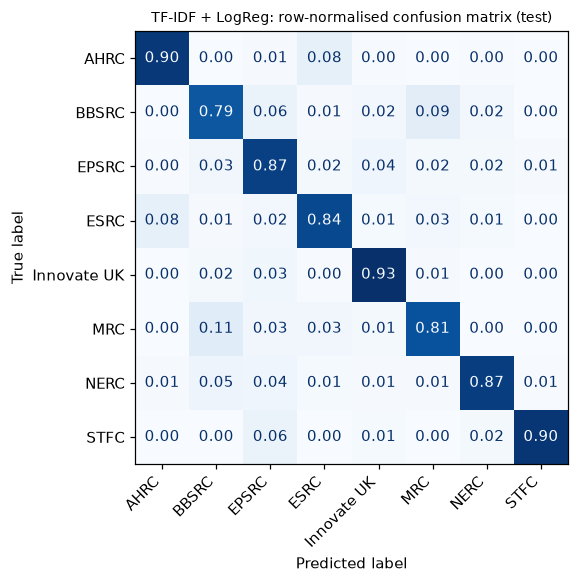

In [27]:
prob_models = res[~res.key.isin(["dummy", "svm"])]   # models that output probabilities (needed for confidence)
best_key = prob_models.loc[prob_models.cv_macroF1.idxmax(), "key"]; best_name = prob_models.loc[prob_models.cv_macroF1.idxmax(), "model"]
print("analysed model:", best_name)
pred = PROBA[best_key].argmax(1)
print(classification_report(y_te, pred, target_names=COUNCILS, digits=3))
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred, normalize="true"), display_labels=COUNCILS).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title(f"{best_name}: row-normalised confusion matrix (test)", fontsize=9); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.savefig(f"{FIG}/confusion_matrix.png", dpi=150); plt.show()

In [28]:
cm = pd.DataFrame(confusion_matrix(y_te, pred), index=COUNCILS, columns=COUNCILS)
off = cm.where(~np.eye(len(COUNCILS), dtype=bool)).stack().sort_values(ascending=False).head(6)
print("Most frequent confusions (true -> predicted):\n", off.to_string())
wrong = te.assign(pred=le.inverse_transform(pred), conf=PROBA[best_key].max(1))[pred != y_te]
for (t, p_), _ in off.head(3).items():
    ex = wrong[(wrong.lead_funder == t) & (wrong.pred == p_)].sort_values("conf", ascending=False).head(2)
    for _, r in ex.iterrows():
        print(f"\n[{t} -> {p_}, conf {r.conf:.2f}] {r.title} | {r.grant_category}\n   {r.abstract[:260]}...")

Most frequent confusions (true -> predicted):
 BBSRC        MRC            243.0
EPSRC        Innovate UK    228.0
MRC          BBSRC          227.0
EPSRC        BBSRC          194.0
Innovate UK  EPSRC          168.0
AHRC         ESRC           160.0

[BBSRC -> MRC, conf 0.99] Comprehensive analysis of T-cell receptor degeneracy and T-cell crossreactivity | Research Grant
   T-cells are white blood cells designed to protect our bodies from infection. The devastating effects of low numbers of just one type of T-cell are all too evident in HIV-AIDS. T-cells perform extremely important roles because: (1) They orchestrate immunity and...

[BBSRC -> MRC, conf 0.99] Role of the FoxN1 gene as a central regulator of epidermal planar cell polarity signaling expression and function | Research Grant
   Summary: 

1. Context of the research

During development, planar cell polarity (PCP) is an important mechanism to align cells and tissues along the main axis of the body. Currently we have a known

In [29]:
conf = PROBA[best_key].max(1)
bins = pd.cut(conf, [0, .4, .6, .8, 1.0])
calib = pd.DataFrame({"confidence": bins, "correct": pred == y_te}).groupby("confidence", observed=True).correct.agg(["mean", "size"]).round(3)
print("Accuracy by top-probability band (used for the app's low-confidence warning):"); calib

Accuracy by top-probability band (used for the app's low-confidence warning):


,mean,size
confidence,,
"(0.0, 0.4]",0.373,134
"(0.4, 0.6]",0.503,1589
"(0.6, 0.8]",0.656,2607
"(0.8, 1.0]",0.935,18318


### 8.1 Explaining a prediction, and checking the explanation is faithful (v2)
For a linear model the evidence for council c is the sum over words of tfidf(word) × weight(c, word), so the
words with the largest contributions explain the prediction exactly (no approximation such as LIME is
needed). The app shows them. To check that they really drive the prediction we use a deletion test on 1,000
test projects: remove the 5 top-contributing words, or 5 random words from the same text, and measure the
drop in the probability of the predicted council.

In [30]:
from sklearn.preprocessing import normalize
clf_lr, vocab = FITTED["lr"], tfidf.get_feature_names_out()
def explain(x, c, k=8):
    """Top-k (word, contribution) pairs for class c given one TF-IDF row x."""
    contrib = x.multiply(clf_lr.coef_[c]).tocsr()
    order = np.argsort(-contrib.data)[:k]
    return [(vocab[contrib.indices[j]], float(contrib.data[j])) for j in order if contrib.data[j] > 0]
rng = np.random.RandomState(SEED); sample = rng.choice(len(te), min(1000, len(te)), replace=False)
drops = {"top-5 explanation words removed": [], "5 random words removed": []}; flips = {k: 0 for k in drops}
for i in sample:
    x = X_te_tfidf[i]; p0 = clf_lr.predict_proba(x)[0]; c = p0.argmax()
    contrib = x.multiply(clf_lr.coef_[c]).tocsr()
    top = contrib.indices[np.argsort(-contrib.data)[:5]]
    rnd = rng.choice(x.indices, size=min(5, x.nnz), replace=False)
    for name, cols in [("top-5 explanation words removed", top), ("5 random words removed", rnd)]:
        x2 = x.copy().tolil(); x2[0, cols] = 0; x2 = normalize(x2.tocsr())
        p1 = clf_lr.predict_proba(x2)[0]
        drops[name].append(p0[c] - p1[c]); flips[name] += int(p1.argmax() != c)
faith = pd.DataFrame({"deletion": list(drops), "mean drop in predicted-council probability": [np.mean(v) for v in drops.values()],
                      "prediction changed": [flips[k] / len(sample) for k in drops]}).round(3)
ex = te.iloc[sample[0]]
print("Example:", ex.title, "| true:", ex.lead_funder, "| predicted:", COUNCILS[PROBA['lr'][sample[0]].argmax()])
print("Top words:", explain(X_te_tfidf[sample[0]], PROBA["lr"][sample[0]].argmax()))
faith

Example: Investigating deliberative methods for setting a monetary capability threshold in the context of social care and public health | true: MRC | predicted: ESRC
Top words: [('social', 0.7699392437934875), ('economic', 0.345303475856781), ('participants', 0.3346226215362549), ('care', 0.2887825667858124), ('interviews', 0.28322282433509827), ('society', 0.2698255777359009), ('sufficient', 0.24740996956825256), ('monetary', 0.2465631663799286)]


,deletion,mean drop in predicted-council probability,prediction changed
0,top-5 explanation words removed,0.221,0.265
1,5 random words removed,0.007,0.022


## 9. Choosing the model to deploy: quality vs latency, size and memory
A deployed configuration = a classifier **plus** the similar-project search it needs. TF-IDF classifiers
are paired with TF-IDF search (no neural encoder needed at all); embedding classifiers and the ensemble
with BGE/MiniLM search (the encoder is loaded anyway). The Linear SVM is not deployable as it stands
because it gives no probabilities, which the app shows.

Each configuration is saved as the app would load it; a **fresh Python process** loads it and handles 50
test abstracts one at a time (classify + search the index). We record artefact size, peak resident memory
(VmHWM), cold-load time and single-query latency, with torch limited to 2 threads like a small cloud VM.
Streamlit Community Cloud gives roughly 690 MB–2.7 GB RAM per app (Streamlit docs, checked Nov 2026).

**Selection rule (fixed before looking at the results):** keep configurations with peak RAM < 1,000 MB
and p95 latency < 1 s; take the best **cross-validated** macro-F1 (the test set is not used to choose);
if a lighter configuration is within 0.01 CV macro-F1 of it, prefer the lighter one.

In [31]:
import scipy.sparse as sp
def save(obj, path):
    with open(path, "wb") as f: pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    return os.path.getsize(path) / 1e6
C_DIR = f"{MODELS}/cand"; os.makedirs(C_DIR, exist_ok=True)
SIZE = {"tfidf_lr": save({"vec": tfidf, "clf": FITTED["lr"]}, f"{C_DIR}/tfidf_lr.pkl"),
        "tfidf_nb": save({"vec": tfidf, "clf": FITTED["nb"]}, f"{C_DIR}/tfidf_nb.pkl"),
        "minilm_lr": save({"clf": FITTED["minilm_lr"]}, f"{C_DIR}/minilm_lr.pkl"),
        "bge_lr": save({"clf": FITTED["bge_lr"]}, f"{C_DIR}/bge_lr.pkl"),
        "bge_mlp": save({"clf": FITTED["bge_mlp"]}, f"{C_DIR}/bge_mlp.pkl")}
sp.save_npz(f"{C_DIR}/index_tfidf.npz", X_tr_tfidf.astype(np.float32))
for k in EMB:
    np.save(f"{C_DIR}/index_{k}.npy", EMB[k][0].astype(np.float16))
IDX_MB = {"tfidf": os.path.getsize(f"{C_DIR}/index_tfidf.npz") / 1e6,
          **{k: os.path.getsize(f"{C_DIR}/index_{k}.npy") / 1e6 for k in EMB}}
ENC_MB = {}
for k, name in EMB_MODELS.items():  # size of the downloaded sentence-transformer weights
    p = glob.glob(os.path.expanduser(f"~/.cache/huggingface/hub/models--{name.replace('/', '--')}/blobs/*"))
    ENC_MB[k] = sum(os.path.getsize(x) for x in p) / 1e6
print("classifier MB", {k: round(v, 1) for k, v in SIZE.items()}, "\nindex MB", {k: round(v, 1) for k, v in IDX_MB.items()},
      "\nencoder MB", {k: round(v, 1) for k, v in ENC_MB.items()})

classifier MB {'tfidf_lr': 14.4, 'tfidf_nb': 35.2, 'minilm_lr': 0.0, 'bge_lr': 0.0, 'bge_mlp': 4.8} 
index MB {'tfidf': 102.1, 'minilm': 69.6, 'bge': 69.6} 
encoder MB {'minilm': 91.6, 'bge': 134.5}


In [32]:
BENCH = r'''
import sys, time, pickle, json, numpy as np
def hwm_mb():
    """Peak resident memory of THIS process (VmHWM). ru_maxrss is not used because Linux carries the
    parent's high-water mark into a forked child, which would make every candidate look the same."""
    for line in open("/proc/self/status"):
        if line.startswith("VmHWM"):
            return int(line.split()[1]) / 1024
clfs, retr, cdir, texts = sys.argv[1].split("+"), sys.argv[2], sys.argv[3], json.load(open(sys.argv[4]))
ENC = {"minilm": "sentence-transformers/all-MiniLM-L6-v2", "bge": "BAAI/bge-small-en-v1.5"}
t0 = time.time()
models = {c: pickle.load(open(f"{cdir}/{c}.pkl", "rb")) for c in clfs}
need = {c.split("_")[0] for c in clfs if not c.startswith("tfidf")} | ({retr} if retr != "tfidf" else set())
vec = next((m["vec"] for m in models.values() if "vec" in m), None)
if retr == "tfidf":
    import scipy.sparse as sp; index = sp.load_npz(f"{cdir}/index_tfidf.npz").tocsr()
    if vec is None: vec = pickle.load(open(f"{cdir}/tfidf_lr.pkl", "rb"))["vec"]
else:
    index = np.load(f"{cdir}/index_{retr}.npy")
enc = {}
if need:
    import torch; torch.set_num_threads(2)
    from sentence_transformers import SentenceTransformer
    for k in need:
        enc[k] = SentenceTransformer(ENC[k], device="cpu"); enc[k].max_seq_length = 256
load_s = time.time() - t0
def query(t):
    X = vec.transform([t]) if vec is not None else None
    E = {k: e.encode([t], normalize_embeddings=True)[0].astype(np.float32) for k, e in enc.items()}
    p = np.mean([m["clf"].predict_proba(X if c.startswith("tfidf") else E[c.split("_")[0]][None, :])[0]
                 for c, m in models.items()], axis=0)
    if retr == "tfidf":
        s = (index @ X.T).toarray().ravel()
    else:
        s = np.concatenate([index[i:i + 20000].astype(np.float32) @ E[retr] for i in range(0, len(index), 20000)])
    return p.argmax(), np.argpartition(-s, 10)[:10]
query(texts[0])
lat = []
for t in texts:
    s0 = time.time(); query(t); lat.append(time.time() - s0)
print(json.dumps({"load_s": load_s, "median_ms": 1000 * float(np.median(lat)), "p95_ms": 1000 * float(np.percentile(lat, 95)),
                  "peak_rss_mb": hwm_mb()}))
'''
open(f"{C_DIR}/bench.py", "w").write(BENCH)
json.dump(te.text.sample(50, random_state=SEED).tolist(), open(f"{C_DIR}/bench_texts.json", "w"))
CONFIGS = {  # name in results table: (classifier files, retriever)
    "TF-IDF + LogReg": ("tfidf_lr", "tfidf"), "TF-IDF + ComplementNB": ("tfidf_nb", "tfidf"),
    "MINILM emb + LogReg": ("minilm_lr", "minilm"), "BGE emb + LogReg": ("bge_lr", "bge"),
    "BGE emb + MLP": ("bge_mlp", "bge"), "Ensemble: TF-IDF LR + BGE LR": ("tfidf_lr+bge_lr", "bge")}
bench = {}
for name, (clfs, retr) in CONFIGS.items():
    out = subprocess.run([sys.executable, f"{C_DIR}/bench.py", clfs, retr, C_DIR, f"{C_DIR}/bench_texts.json"],
                         capture_output=True, text=True, env={**os.environ, "TOKENIZERS_PARALLELISM": "false"})
    bench[name] = json.loads(out.stdout.strip().splitlines()[-1]); print(f"{name:30s}", {k: round(v, 1) for k, v in bench[name].items()})

TF-IDF + LogReg                {'load_s': 2.8, 'median_ms': 56.6, 'p95_ms': 68.3, 'peak_rss_mb': 369.6}


TF-IDF + ComplementNB          {'load_s': 1.8, 'median_ms': 56.5, 'p95_ms': 71.3, 'peak_rss_mb': 392.8}


MINILM emb + LogReg            {'load_s': 4.2, 'median_ms': 173.9, 'p95_ms': 205.4, 'peak_rss_mb': 713.8}


BGE emb + LogReg               {'load_s': 3.9, 'median_ms': 190.2, 'p95_ms': 216.0, 'peak_rss_mb': 756.5}


BGE emb + MLP                  {'load_s': 3.8, 'median_ms': 191.8, 'p95_ms': 198.6, 'peak_rss_mb': 756.4}


Ensemble: TF-IDF LR + BGE LR   {'load_s': 3.8, 'median_ms': 189.6, 'p95_ms': 205.8, 'peak_rss_mb': 789.9}


In [33]:
RET_NAME = {"tfidf": "TF-IDF cosine", "minilm": "MiniLM cosine", "bge": "BGE cosine"}
rows = []
for name, (clfs, retr) in CONFIGS.items():
    r = res.set_index("model").loc[name]
    encs = {c.split("_")[0] for c in clfs.split("+") if not c.startswith("tfidf")} | ({retr} if retr != "tfidf" else set())
    rows.append({"configuration": name, "search": RET_NAME[retr], "CV macro-F1": r.cv_macroF1, "test macro-F1": r.macro_F1,
                 "test top-3 acc": r.top3_acc, "search P@10 topic": ret.set_index("retriever").loc[RET_NAME[retr], "P@10 shares a research topic"],
                 "disk MB": sum(SIZE[c] for c in clfs.split("+")) + IDX_MB[retr] + sum(ENC_MB[e] for e in encs),
                 "peak RAM MB": bench[name]["peak_rss_mb"], "cold load s": bench[name]["load_s"],
                 "latency ms (median)": bench[name]["median_ms"], "latency ms (p95)": bench[name]["p95_ms"]})
sel = pd.DataFrame(rows).set_index("configuration").round(3).sort_values("CV macro-F1", ascending=False)
ok_cfg = sel[(sel["peak RAM MB"] < 1000) & (sel["latency ms (p95)"] < 1000)]
best_cv = ok_cfg["CV macro-F1"].max()
near = ok_cfg[ok_cfg["CV macro-F1"] >= best_cv - 0.01]
DEPLOY = near.sort_values(["peak RAM MB", "latency ms (median)"]).index[0]
print("passes resource limits:", list(ok_cfg.index)); print("within 0.01 of best CV macro-F1:", list(near.index))
print("==> deploy:", DEPLOY)
sel.to_csv(f"{MODELS}/deployment_selection.csv"); sel

passes resource limits: ['TF-IDF + LogReg', 'Ensemble: TF-IDF LR + BGE LR', 'BGE emb + MLP', 'TF-IDF + ComplementNB', 'BGE emb + LogReg', 'MINILM emb + LogReg']
within 0.01 of best CV macro-F1: ['TF-IDF + LogReg', 'Ensemble: TF-IDF LR + BGE LR']
==> deploy: TF-IDF + LogReg


,search,CV macro-F1,test macro-F1,test top-3 acc,search P@10 topic,disk MB,peak RAM MB,cold load s,latency ms (median),latency ms (p95)
configuration,,,,,,,,,,
TF-IDF + LogReg,TF-IDF cosine,0.858,0.862,0.992,0.350,116.472,369.582,2.807,56.634,68.275
Ensemble: TF-IDF LR + BGE LR,BGE cosine,0.856,0.858,0.992,0.330,218.483,789.852,3.759,189.609,205.817
BGE emb + MLP,BGE cosine,0.819,0.820,0.988,0.330,208.913,756.441,3.836,191.769,198.555
TF-IDF + ComplementNB,TF-IDF cosine,0.808,0.807,0.975,0.350,137.272,392.773,1.753,56.528,71.264
BGE emb + LogReg,BGE cosine,0.793,0.793,0.982,0.330,204.088,756.500,3.883,190.159,215.969
MINILM emb + LogReg,MiniLM cosine,0.783,0.784,0.981,0.346,161.161,713.758,4.173,173.879,205.370


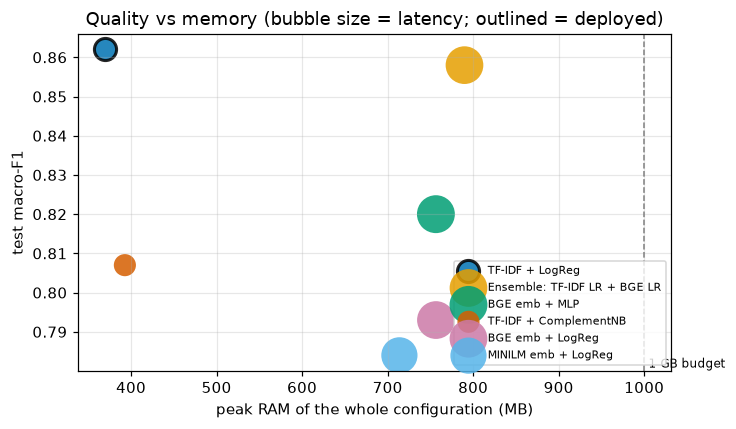

In [34]:
fig, ax = plt.subplots(figsize=(6.8, 4))
for i, (n, r) in enumerate(sel.iterrows()):
    ax.scatter(r["peak RAM MB"], r["test macro-F1"], s=40 + r["latency ms (median)"] * 3, color=CB[i % 8], label=n, alpha=.85,
               edgecolor="k" if n == DEPLOY else "none", linewidth=2)
ax.axvline(1000, ls="--", c="grey", lw=1); ax.text(1005, ax.get_ylim()[0], "1 GB budget", fontsize=8, va="bottom")
ax.set_xlabel("peak RAM of the whole configuration (MB)"); ax.set_ylabel("test macro-F1")
ax.set_title("Quality vs memory (bubble size = latency; outlined = deployed)"); ax.grid(alpha=.3); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG}/deployment_tradeoff.png", dpi=150); plt.show()

## 10. Export the deployed configuration for the Streamlit app
The chosen configuration is refitted on **all** clean projects (train + test) with the tuned
hyper-parameters, so the product uses every project; the reported scores are from the held-out run above.

In [35]:
APP = "app/assets"; os.makedirs(APP, exist_ok=True)
for f in glob.glob(f"{APP}/*"):
    os.remove(f)
clfs, retr = CONFIGS[DEPLOY]
X_all = E_all = None
manifest = {"classifiers": [], "retriever": retr}
for c in clfs.split("+"):
    if c.startswith("tfidf"):
        if X_all is None:
            tf_final = TfidfVectorizer(**tfidf.get_params()); X_all = tf_final.fit_transform(df.text)
        m = (LogisticRegression(C=TUNING["lr"][0], class_weight="balanced", max_iter=300) if c == "tfidf_lr"
             else ComplementNB(alpha=TUNING["nb"][0])).fit(X_all, y_all)
        save({"vec": tf_final, "clf": m, "classes": COUNCILS}, f"{APP}/{c}.pkl")
    else:
        k = c.split("_")[0]; E = np.load(f"{PROC}/emb_{k}.npy")
        m = (LogisticRegression(C=TUNING[c][0], class_weight="balanced", max_iter=2000) if c.endswith("_lr") else
             MLPClassifier(hidden_layer_sizes=(int(TUNING[c][0]),), alpha=1e-4, early_stopping=True, validation_fraction=0.1,
                           max_iter=60, random_state=SEED)).fit(E, y_all)
        save({"clf": m, "classes": COUNCILS, "encoder": EMB_MODELS[k]}, f"{APP}/{c}.pkl")
    manifest["classifiers"].append({"file": f"{c}.pkl", "input": "tfidf" if c.startswith("tfidf") else c.split("_")[0]})
if retr == "tfidf":
    if X_all is None:
        tf_final = TfidfVectorizer(**tfidf.get_params()); X_all = tf_final.fit_transform(df.text)
        save({"vec": tf_final, "classes": COUNCILS}, f"{APP}/tfidf_vec.pkl")
    sp.save_npz(f"{APP}/index_tfidf.npz", X_all.astype(np.float32))
    manifest["index"] = "index_tfidf.npz"
else:
    np.save(f"{APP}/index_{retr}_f16.npy", np.load(f"{PROC}/emb_{retr}.npy").astype(np.float16))  # half the RAM
    manifest["index"] = f"index_{retr}_f16.npy"; manifest["encoder"] = EMB_MODELS[retr]
meta = df[["project_id", "grant_ref", "title", "lead_funder", "grant_category", "lead_org_name", "department",
           "award_gbp", "fund_start", "fund_end", "gtr_url"]].copy()
meta["start_year"] = meta.fund_start.dt.year.astype("Int64")
meta.to_parquet(f"{APP}/projects_meta.parquet", index=False)
dep_key = {"TF-IDF + LogReg": "lr", "TF-IDF + ComplementNB": "nb", "MINILM emb + LogReg": "minilm_lr", "BGE emb + LogReg": "bge_lr",
           "BGE emb + MLP": "bge_mlp", "Ensemble: TF-IDF LR + BGE LR": "ens"}[DEPLOY]
r_dep = res.set_index("model").loc[DEPLOY]
P_dep = temp_scale(PROBA[dep_key], T_LR) if dep_key == "lr" else PROBA[dep_key]   # the app shows calibrated probabilities
dep_pred = P_dep.argmax(1); dep_conf = P_dep.max(1)
acc_band = pd.Series(dep_pred == y_te).groupby(pd.cut(dep_conf, [0, .4, .6, .8, 1.0]), observed=True).mean().round(3)
info = {"deployed_model": DEPLOY, **manifest, "n_projects_index": int(len(df)),
        "data_collected": json.load(open(os.path.join(RAW, "collection_log.json")))["projects"]["collected_utc"],
        "test_macro_f1": float(r_dep.macro_F1), "test_accuracy": float(r_dep.accuracy), "test_top3": float(r_dep.top3_acc),
        "per_class_f1": pd.Series(f1_score(y_te, dep_pred, average=None), index=COUNCILS).round(3).to_dict(),
        "accuracy_by_confidence": {str(k): float(v) for k, v in acc_band.items()},
        "award_coverage": {r["method"]: float(r["coverage of true award"]) for r in award.to_dict("records")},
        "grant_categories": df.grant_category.value_counts().index[:15].tolist(),
        "temperature": T_LR if dep_key == "lr" else 1.0, "calibration": calib_tab.to_dict("records"),
        "retrieval_metrics": retr_metrics.to_dict("records"), "award_regression": award_reg.to_dict("records")}
json.dump(info, open(f"{APP}/model_info.json", "w"), indent=1)
for f in sorted(os.listdir(APP)):
    print(f"{f:28s} {os.path.getsize(f'{APP}/{f}')/1e6:7.1f} MB")
print(json.dumps(info, indent=1))

index_tfidf.npz                128.0 MB
model_info.json                  0.0 MB
projects_meta.parquet           13.5 MB
tfidf_lr.pkl                    14.4 MB
{
 "deployed_model": "TF-IDF + LogReg",
 "classifiers": [
  {
   "file": "tfidf_lr.pkl",
   "input": "tfidf"
  }
 ],
 "retriever": "tfidf",
 "index": "index_tfidf.npz",
 "n_projects_index": 113233,
 "data_collected": "2026-11-23T19:35:16+00:00",
 "test_macro_f1": 0.8615,
 "test_accuracy": 0.8693,
 "test_top3": 0.9916,
 "per_class_f1": {
  "AHRC": 0.899,
  "BBSRC": 0.78,
  "EPSRC": 0.885,
  "ESRC": 0.823,
  "Innovate UK": 0.925,
  "MRC": 0.795,
  "NERC": 0.867,
  "STFC": 0.918
 },
 "accuracy_by_confidence": {
  "(0.0, 0.4]": 0.428,
  "(0.4, 0.6]": 0.517,
  "(0.6, 0.8]": 0.682,
  "(0.8, 1.0]": 0.943
 },
 "award_coverage": {
  "TF-IDF: 10 neighbours, P25-P75": 0.435,
  "TF-IDF: 30 neighbours, P25-P75": 0.522,
  "TF-IDF: 30 neighbours, P10-P90": 0.801,
  "TF-IDF: 30 same-scheme neighbours, P25-P75": 0.52,
  "TF-IDF: 30 same-scheme n

In [36]:
summary = {"clean_table": clean_table.to_dict("records"), "results": res.to_dict("records"), "leak": leak.to_dict("records"),
           "learning_curve": lc.to_dict("records"), "temporal": temporal.to_dict("records"), "retrieval": ret.to_dict("records"),
           "award": award.to_dict("records"), "selection": sel.reset_index().to_dict("records"), "deploy": DEPLOY,
           "calib": calib.reset_index().astype(str).to_dict("records"), "n_clean": len(df), "n_train": len(tr), "n_test": len(te),
           "n_groups": int(df.group.nunique()), "tuning": {k: [float(x) for x in v] for k, v in TUNING.items()},
           "calibration": calib_tab.to_dict("records"), "temperature": T_LR, "cross_country": cross.to_dict("records"),
           "cross_counts": intl.groupby(["source", "expected"]).size().reset_index().astype(str).values.tolist(),
           "cross_per_council": intl.assign(ok=intl.pred == intl.expected).groupby("expected").ok.mean().round(3).to_dict(),
           "nih_pred": intl[intl.source == "NIH"].pred.value_counts(normalize=True).round(3).to_dict(), "n_intl_raw": n0,
           "cross_by_source": by_src.to_dict("records"), "retrieval_metrics": retr_metrics.to_dict("records"), "award_regression": award_reg.to_dict("records"),
           "n_award_test": int(ok_te.sum()), "n_award_train": int(ok_tr.sum()), "hybrid": ret2.to_dict("records"), "faithfulness": faith.to_dict("records")}
json.dump(summary, open(f"{MODELS}/summary.json", "w"), indent=1, default=str)
print("saved models/summary.json")

saved models/summary.json
